# [15.3] QLoRA from Scratch

**Can a small trainable adapter recover a useful rule after we quantize
a pretrained model's frozen weights to four bits?**

Start with a weight vector you can draw by hand. You will build its NF4
quantizer, account for the scale metadata, and add a low-rank update.
Then teach TinyStories a new marker-to-color rule and compare your QLoRA
against BF16 LoRA and full finetuning. The final panels show behavior,
memory use, and the singular values of the learned updates.

Each method appears here as editable code, followed immediately by a
small test. Complete the exercises or reveal the answers as you go.
This is an optional QLoRA companion; it does not replace the core
LoRA, DoRA, subspace, and intruder-dimension material in the roadmap.

## Learning Objectives

1. Implement NF4 lookup quantization, dequantization, and nested scale compression.
2. Audit exact bitsandbytes codebook values, tensor finiteness, packing, and compute dtype.
3. Add visible FP32 LoRA factors around a genuinely materialized nested-NF4 base.
4. Remove name and template confounding with a complete subject-template-label cross.
5. Evaluate marker swaps, marker removal, name-only, random-label, and same-norm controls.
6. Distinguish two-label conditional NLL from full-vocabulary next-token NLL.
7. Compare total resident training state and report a 95% Student-t interval for n=3.
8. Explain which behavior and memory claims your measured controls support.

## Cold Open: Where Do the Missing Bits Go?

A float32 weight uses 32 bits. NF4 picks one of 16 values, so the index
needs four bits. But weights in different blocks need different scales,
and training an adapter also needs gradients and optimizer state.

Predict first: will a 4-bit base make the whole training process eight
times smaller? Will adding one large outlier damage its neighbors?
Keep both predictions; our plots will make the answers visible.

## Setup

In [1]:
import gc
import os
import hashlib
import inspect
import json
import math
import statistics
import sys
import warnings
from dataclasses import asdict
from pathlib import Path
from typing import Any, Callable, Iterable, Sequence

import bitsandbytes as bnb
import copy
import matplotlib.pyplot as plt
import numpy as np
import torch as t
import torch.nn.functional as F
from IPython.display import Image, display
from torch import nn

ROOT = Path.cwd().resolve()
while not (ROOT / "pyproject.toml").exists():
    if ROOT.parent == ROOT:
        raise RuntimeError("Run this notebook from inside the ARENA repository")
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from chapter15_peft_misalignment.exercises.part3_qlora_from_scratch import solutions as reference
from chapter15_peft_misalignment.exercises.part3_qlora_from_scratch import tests
from chapter15_peft_misalignment.exercises.part3_qlora_from_scratch.solutions import (
    DOUBLE_QUANT_BLOCK_SIZE,
    INTENDED_QUANTIZED_SUFFIXES,
    LABEL_TEXT,
    MARKERS,
    MODEL_ID,
    MODEL_REVISION,
    NF4_BLOCK_SIZE,
    TARGET_MODULES,
    BehaviorMetrics,
    DenseLoRALinear,
    DoubleQuantizedScales,
    LearnerFunctions,
    NF4Tensor,
    PromptExample,
    SpectrumMetrics,
    TrainTrace,
)

warnings.filterwarnings("ignore", category=FutureWarning, module="bitsandbytes")
t.manual_seed(0)
print(f"torch={t.__version__}; bitsandbytes={bnb.__version__}; revision={MODEL_REVISION[:12]}")

torch=2.12.1+cu132; bitsandbytes=0.50.2; revision=77f1b168e219


## 1. NF4 Is a Lookup Table

### Exercise: exact blockwise NF4

Implement per-block absmax normalization, nearest-code assignment, and
dequantization from stored codes. Also construct the signed dynamic codebook
used by the nested scale state.

<details><summary>Expected output</summary>

The manual 64-value reconstruction equals bitsandbytes exactly, including
the all-zero block. The NF4 table has 16 values; the nested dynamic table
has 256 finite values matching the expected backend-specific map.

</details>

<details><summary>Help</summary>

Pad only after flattening. Clamp zero scales before division. For the
dynamic table, inspect the bitsandbytes constructor and the endpoints its
blockwise runtime actually materializes.

</details>

In [2]:
def nf4_codebook(*, device: t.device | str = "cpu", dtype: t.dtype = t.float32) -> t.Tensor:
    """Return the canonical bitsandbytes NF4 lookup table in sorted order."""

    return t.tensor(
        [
            -1.0,
            -0.6961928009986877,
            -0.5250730514526367,
            -0.39491748809814453,
            -0.28444138169288635,
            -0.18477343022823334,
            -0.09105003625154495,
            0.0,
            0.07958029955625534,
            0.16093020141124725,
            0.24611230194568634,
            0.33791524171829224,
            0.44070982933044434,
            0.5626170039176941,
            0.7229568362236023,
            1.0,
        ],
        device=device,
        dtype=dtype,
    )

def expected_dynamic_codebook(
    *,
    device: t.device | str = "cpu",
    dtype: t.dtype = t.float32,
) -> t.Tensor:
    """Return the signed dynamic map used by bitsandbytes 0.50.2 on CPU/CUDA.

    Keep all 256 values exact: this backend retains the generated negative
    endpoint (-0.992968738079071), including on CPU. Older backend-specific
    endpoint substitutions must not silently change the current oracle.
    """

    from bitsandbytes import functional as bnb_functional

    return bnb_functional.create_dynamic_map(signed=True).to(device=device, dtype=dtype)

def blockwise_absmax(values: t.Tensor, *, block_size: int = NF4_BLOCK_SIZE) -> t.Tensor:
    """Return one absolute maximum per flattened block, padding the final block with zeros."""

    if block_size <= 0:
        raise ValueError("block_size must be positive")
    if values.numel() == 0:
        raise ValueError("cannot quantize an empty tensor")
    flat = values.detach().float().flatten()
    padded_numel = math.ceil(flat.numel() / block_size) * block_size
    padded = F.pad(flat, (0, padded_numel - flat.numel()))
    return padded.view(-1, block_size).abs().amax(dim=1)

def quantize_nf4(values: t.Tensor, *, block_size: int = NF4_BLOCK_SIZE) -> NF4Tensor:
    """Quantize a tensor by nearest-neighbour lookup after blockwise absmax normalization."""

    scales = blockwise_absmax(values, block_size=block_size)
    flat = values.detach().float().flatten()
    padded_numel = scales.numel() * block_size
    blocks = F.pad(flat, (0, padded_numel - flat.numel())).view(-1, block_size)
    safe_scales = scales.clamp_min(t.finfo(t.float32).tiny)
    normalized = blocks / safe_scales[:, None]
    codebook = nf4_codebook(device=values.device)
    distances = (normalized[..., None] - codebook).abs()
    indices = distances.argmin(dim=-1).to(t.uint8)
    return NF4Tensor(indices, scales.to(values.device), tuple(values.shape), values.numel(), block_size)

def dequantize_nf4(quantized: NF4Tensor, *, dtype: t.dtype = t.float32) -> t.Tensor:
    """Invert ``quantize_nf4`` using the stored code indices and block scales."""

    codebook = nf4_codebook(device=quantized.indices.device)
    blocks = codebook[quantized.indices.long()] * quantized.absmax[:, None]
    return blocks.flatten()[: quantized.numel].reshape(quantized.shape).to(dtype)

def quantization_error(reference: t.Tensor, reconstructed: t.Tensor) -> dict[str, float]:
    """Measure reconstruction error without hiding scale-dependent failures."""

    if reference.shape != reconstructed.shape:
        raise ValueError("reference and reconstructed tensors must have the same shape")
    ref = reference.detach().float().flatten()
    rec = reconstructed.detach().float().flatten()
    error = rec - ref
    signal = ref.square().mean().clamp_min(t.finfo(t.float32).tiny)
    noise = error.square().mean().clamp_min(t.finfo(t.float32).tiny)
    cosine = F.cosine_similarity(ref, rec, dim=0).item() if ref.norm() > 0 and rec.norm() > 0 else 1.0
    return {
        "mse": float(noise.item()),
        "max_abs_error": float(error.abs().max().item()),
        "cosine_similarity": float(cosine),
        "sqnr_db": float((10 * t.log10(signal / noise)).item()),
    }

In [3]:
tests.check_nf4_codebook(nf4_codebook)
tests.check_blockwise_absmax(blockwise_absmax)
tests.check_manual_nf4(quantize_nf4, dequantize_nf4)
print("Exact NF4 lookup, padding, and zero-block checks passed.")

Exact NF4 lookup, padding, and zero-block checks passed.


<details>
<summary>Solution</summary>

```python
def nf4_codebook(*, device: t.device | str = "cpu", dtype: t.dtype = t.float32) -> t.Tensor:
    """Return the canonical bitsandbytes NF4 lookup table in sorted order."""

    return t.tensor(
        [
            -1.0,
            -0.6961928009986877,
            -0.5250730514526367,
            -0.39491748809814453,
            -0.28444138169288635,
            -0.18477343022823334,
            -0.09105003625154495,
            0.0,
            0.07958029955625534,
            0.16093020141124725,
            0.24611230194568634,
            0.33791524171829224,
            0.44070982933044434,
            0.5626170039176941,
            0.7229568362236023,
            1.0,
        ],
        device=device,
        dtype=dtype,
    )

def expected_dynamic_codebook(
    *,
    device: t.device | str = "cpu",
    dtype: t.dtype = t.float32,
) -> t.Tensor:
    """Return the signed dynamic map used by bitsandbytes 0.50.2 on CPU/CUDA.

    Keep all 256 values exact: this backend retains the generated negative
    endpoint (-0.992968738079071), including on CPU. Older backend-specific
    endpoint substitutions must not silently change the current oracle.
    """

    from bitsandbytes import functional as bnb_functional

    return bnb_functional.create_dynamic_map(signed=True).to(device=device, dtype=dtype)

def blockwise_absmax(values: t.Tensor, *, block_size: int = NF4_BLOCK_SIZE) -> t.Tensor:
    """Return one absolute maximum per flattened block, padding the final block with zeros."""

    if block_size <= 0:
        raise ValueError("block_size must be positive")
    if values.numel() == 0:
        raise ValueError("cannot quantize an empty tensor")
    flat = values.detach().float().flatten()
    padded_numel = math.ceil(flat.numel() / block_size) * block_size
    padded = F.pad(flat, (0, padded_numel - flat.numel()))
    return padded.view(-1, block_size).abs().amax(dim=1)

def quantize_nf4(values: t.Tensor, *, block_size: int = NF4_BLOCK_SIZE) -> NF4Tensor:
    """Quantize a tensor by nearest-neighbour lookup after blockwise absmax normalization."""

    scales = blockwise_absmax(values, block_size=block_size)
    flat = values.detach().float().flatten()
    padded_numel = scales.numel() * block_size
    blocks = F.pad(flat, (0, padded_numel - flat.numel())).view(-1, block_size)
    safe_scales = scales.clamp_min(t.finfo(t.float32).tiny)
    normalized = blocks / safe_scales[:, None]
    codebook = nf4_codebook(device=values.device)
    distances = (normalized[..., None] - codebook).abs()
    indices = distances.argmin(dim=-1).to(t.uint8)
    return NF4Tensor(indices, scales.to(values.device), tuple(values.shape), values.numel(), block_size)

def dequantize_nf4(quantized: NF4Tensor, *, dtype: t.dtype = t.float32) -> t.Tensor:
    """Invert ``quantize_nf4`` using the stored code indices and block scales."""

    codebook = nf4_codebook(device=quantized.indices.device)
    blocks = codebook[quantized.indices.long()] * quantized.absmax[:, None]
    return blocks.flatten()[: quantized.numel].reshape(quantized.shape).to(dtype)

def quantization_error(reference: t.Tensor, reconstructed: t.Tensor) -> dict[str, float]:
    """Measure reconstruction error without hiding scale-dependent failures."""

    if reference.shape != reconstructed.shape:
        raise ValueError("reference and reconstructed tensors must have the same shape")
    ref = reference.detach().float().flatten()
    rec = reconstructed.detach().float().flatten()
    error = rec - ref
    signal = ref.square().mean().clamp_min(t.finfo(t.float32).tiny)
    noise = error.square().mean().clamp_min(t.finfo(t.float32).tiny)
    cosine = F.cosine_similarity(ref, rec, dim=0).item() if ref.norm() > 0 and rec.norm() > 0 else 1.0
    return {
        "mse": float(noise.item()),
        "max_abs_error": float(error.abs().max().item()),
        "cosine_similarity": float(cosine),
        "sqnr_db": float((10 * t.log10(signal / noise)).item()),
    }
```

</details>

## 2. Nested Quantization and a Fail-Closed `QuantState` Audit

### Exercise: formulas, allocated tensors, and corrupt-state rejection

Reconstruct mean-centered scales, separate the amortized paper formula
from a tail-aware logical layout, then measure every unique materialized
tensor. The audit must compare all 16 NF4 values and all 256 dynamic-map
values, reject every non-finite nested tensor, and verify finite
dequantization.

For this first derivation use uniform signed-int8 scale codes. This
arithmetic exercise differs from bitsandbytes' nonuniform dynamic
scale map. The real model below uses and audits the latter; do not
treat the toy scale error as an exact kernel-parity measurement.

<details><summary>Expected output</summary>

`paper amortized < tail-aware small-tensor formula < actual small-layer
storage`; packed bytes equal `ceil(numel / 2)`. Changing any codebook value
or inserting NaN/Inf into offset or nested absmax raises `RuntimeError`.

</details>

<details><summary>Help</summary>

Length and dtype checks cannot detect a subtly corrupt lookup table. Use
exact tensor equality against independently constructed expected values,
and apply `isfinite` to every tensor reachable through `state2`.

</details>

In [4]:
def _tensor_storage_key(tensor: t.Tensor) -> tuple[str, int, int]:
    storage = tensor.untyped_storage()
    return str(tensor.device), storage.data_ptr(), storage.nbytes()

def _unique_tensor_storage_bytes(tensors: Iterable[t.Tensor]) -> int:
    seen: set[tuple[str, int, int]] = set()
    total = 0
    for tensor in tensors:
        key = _tensor_storage_key(tensor)
        if key not in seen:
            seen.add(key)
            total += tensor.untyped_storage().nbytes()
    return total

def _quant_state_tensors(state: Any, *, prefix: str = "quant_state") -> list[tuple[str, t.Tensor]]:
    if state is None:
        return []
    tensors = []
    for field in ("absmax", "code", "offset"):
        value = getattr(state, field, None)
        if isinstance(value, t.Tensor):
            tensors.append((f"{prefix}.{field}", value))
    tensors.extend(_quant_state_tensors(getattr(state, "state2", None), prefix=f"{prefix}.state2"))
    return tensors

def _require_finite_tensor(value: Any, *, name: str) -> t.Tensor:
    if not isinstance(value, t.Tensor):
        raise RuntimeError(f"{name} must be a materialized tensor")
    if not bool(t.isfinite(value.detach().float()).all().item()):
        raise RuntimeError(f"{name} contains non-finite values")
    return value


def double_quantize_scales(
    scales: t.Tensor,
    *,
    block_size: int = DOUBLE_QUANT_BLOCK_SIZE,
) -> DoubleQuantizedScales:
    """Toy nested quantization: mean-center scales, then quantize each group to signed int8.

    bitsandbytes also mean-centers first-level absmax values and block-quantizes them.
    This transparent oracle uses a uniform signed-int8 code so every stored bit is easy
    to account for; the real CUDA path uses bitsandbytes' ``compress_statistics=True``.
    """

    if block_size <= 0:
        raise ValueError("block_size must be positive")
    if scales.numel() == 0 or (scales < 0).any():
        raise ValueError("scales must be a non-empty non-negative tensor")
    flat = scales.detach().float().flatten()
    offset = flat.mean()
    centered = flat - offset
    padded_numel = math.ceil(flat.numel() / block_size) * block_size
    blocks = F.pad(centered, (0, padded_numel - flat.numel())).view(-1, block_size)
    second_absmax = blocks.abs().amax(dim=1)
    safe = second_absmax.clamp_min(t.finfo(t.float32).tiny)
    codes = t.round(127 * blocks / safe[:, None]).clamp(-127, 127).to(t.int8)
    return DoubleQuantizedScales(codes, offset, second_absmax, flat.numel(), block_size)

def dequantize_scales(quantized: DoubleQuantizedScales) -> t.Tensor:
    """Dequantize the transparent nested-scale oracle."""

    centered = quantized.codes.float() * quantized.second_absmax[:, None] / 127
    return centered.flatten()[: quantized.numel] + quantized.offset

def nf4_storage_accounting(
    *,
    numel: int,
    block_size: int = NF4_BLOCK_SIZE,
    double_quant_block_size: int = DOUBLE_QUANT_BLOCK_SIZE,
) -> dict[str, float | int]:
    """Separate the paper's amortized formula from a tail-aware byte layout.

    Neither formula is a measurement of a materialized bitsandbytes layer. Use
    ``linear4bit_storage_accounting`` for that; its total includes codebooks and
    every tensor in the nested ``QuantState``.
    """

    if numel <= 0 or block_size <= 0 or double_quant_block_size <= 0:
        raise ValueError("numel and block sizes must be positive")
    paper_single_bpp = 4 + 32 / block_size
    paper_double_bpp = 4 + 8 / block_size + 32 / (block_size * double_quant_block_size)
    packed_value_bytes = math.ceil(numel / 2)
    blocks = math.ceil(numel / block_size)
    second_blocks = math.ceil(blocks / double_quant_block_size)
    single_bytes = packed_value_bytes + 4 * blocks
    double_bytes = packed_value_bytes + blocks + 4 * second_blocks + 4
    return {
        "numel": numel,
        "blocks": blocks,
        "second_blocks": second_blocks,
        "paper_amortized_single_bits_per_parameter": paper_single_bpp,
        "paper_amortized_double_bits_per_parameter": paper_double_bpp,
        "tail_aware_packed_value_bytes": packed_value_bytes,
        "tail_aware_single_bytes": single_bytes,
        "tail_aware_double_bytes": double_bytes,
        "tail_aware_single_bits_per_parameter": 8 * single_bytes / numel,
        "tail_aware_double_bits_per_parameter": 8 * double_bytes / numel,
        "tail_aware_metadata_savings_bytes": single_bytes - double_bytes,
        # Backward-compatible names are explicitly the tail-aware formula, not
        # measurements from a Linear4bit allocation.
        "packed_value_bits": 8 * packed_value_bytes,
        "single_quant_bits": 8 * single_bytes,
        "double_quant_bits": 8 * double_bytes,
        "single_bits_per_parameter": 8 * single_bytes / numel,
        "double_bits_per_parameter": 8 * double_bytes / numel,
        "metadata_savings_bits": 8 * (single_bytes - double_bytes),
    }

def linear4bit_storage_accounting(layer: nn.Module) -> dict[str, Any]:
    """Measure a materialized Linear4bit, including codebooks and nested state."""

    from bitsandbytes.nn import Linear4bit, Params4bit

    if not isinstance(layer, Linear4bit) or not isinstance(layer.weight, Params4bit):
        raise TypeError("layer must be an actual bitsandbytes Linear4bit with Params4bit weight")
    state = getattr(layer.weight, "quant_state", None)
    if state is None or not bool(getattr(layer.weight, "bnb_quantized", False)):
        raise RuntimeError("Linear4bit weight is declared but unmaterialized")
    state_tensors = _quant_state_tensors(state)
    state_records = {
        name: {
            "shape": list(value.shape),
            "dtype": str(value.dtype),
            "storage_bytes": value.untyped_storage().nbytes(),
            "all_finite": bool(t.isfinite(value.detach().float()).all().item()),
        }
        for name, value in state_tensors
    }
    original_numel = math.prod(int(dim) for dim in state.shape)
    formula = nf4_storage_accounting(
        numel=original_numel,
        block_size=int(state.blocksize),
        double_quant_block_size=int(state.state2.blocksize) if state.state2 is not None else DOUBLE_QUANT_BLOCK_SIZE,
    )
    packed_weight_bytes = layer.weight.untyped_storage().nbytes()
    bias_bytes = 0 if layer.bias is None else layer.bias.untyped_storage().nbytes()
    actual_tensors = [layer.weight]
    if layer.bias is not None:
        actual_tensors.append(layer.bias)
    actual_tensors.extend(value for _, value in state_tensors)
    return {
        "original_numel": original_numel,
        "packed_weight_shape": list(layer.weight.shape),
        "packed_weight_dtype": str(layer.weight.dtype),
        "packed_weight_bytes": packed_weight_bytes,
        "expected_packed_weight_bytes": math.ceil(original_numel / 2),
        "bias_bytes": bias_bytes,
        "quant_state_tensor_bytes": _unique_tensor_storage_bytes(value for _, value in state_tensors),
        "quant_state_tensors": state_records,
        "actual_tensor_bytes_including_codebooks": _unique_tensor_storage_bytes(actual_tensors),
        "paper_amortized_double_bits_per_parameter": formula[
            "paper_amortized_double_bits_per_parameter"
        ],
        "tail_aware_formula_bytes_excluding_codebooks": formula["tail_aware_double_bytes"],
    }

def audit_linear4bit(
    layer: nn.Module,
    *,
    expected_compute_dtype: t.dtype,
    expected_storage_dtype: t.dtype = t.uint8,
) -> dict[str, Any]:
    """Fail closed unless a layer has a real nested NF4 packed state."""

    from bitsandbytes.nn import Linear4bit, Params4bit

    if not isinstance(layer, Linear4bit) or not isinstance(getattr(layer, "weight", None), Params4bit):
        raise TypeError("expected an actual bitsandbytes Linear4bit with Params4bit weight")
    weight = layer.weight
    state = getattr(weight, "quant_state", None)
    if state is None or not bool(getattr(weight, "bnb_quantized", False)):
        raise RuntimeError("Linear4bit is unmaterialized: packed weight and QuantState are required")
    if getattr(weight, "quant_type", None) != "nf4" or getattr(state, "quant_type", None) != "nf4":
        raise RuntimeError("materialized layer is not NF4")
    if weight.dtype != expected_storage_dtype or getattr(layer, "quant_storage", None) != expected_storage_dtype:
        raise RuntimeError(f"expected packed storage dtype {expected_storage_dtype}, got {weight.dtype}")
    if getattr(layer, "compute_dtype", None) != expected_compute_dtype:
        raise RuntimeError(f"expected compute dtype {expected_compute_dtype}, got {layer.compute_dtype}")
    if not bool(getattr(state, "nested", False)) or state.state2 is None:
        raise RuntimeError("nested QuantState is required (compress_statistics=True)")
    _require_finite_tensor(weight, name="packed weight")
    if layer.bias is not None:
        _require_finite_tensor(layer.bias, name="bias")
    _require_finite_tensor(getattr(state, "offset", None), name="quant_state.offset")
    first_absmax = _require_finite_tensor(getattr(state, "absmax", None), name="quant_state.absmax")
    nf4_state_code = _require_finite_tensor(getattr(state, "code", None), name="quant_state.code")
    nested_absmax = _require_finite_tensor(
        getattr(state.state2, "absmax", None), name="quant_state.state2.absmax"
    )
    dynamic_state_code = _require_finite_tensor(
        getattr(state.state2, "code", None), name="quant_state.state2.code"
    )
    if first_absmax.dtype != t.uint8:
        raise RuntimeError("nested first-level absmax must be packed as uint8")
    for name, value in _quant_state_tensors(state):
        _require_finite_tensor(value, name=name)
    if int(getattr(state, "blocksize", -1)) != NF4_BLOCK_SIZE:
        raise RuntimeError(f"NF4 QuantState block size must be {NF4_BLOCK_SIZE}")
    if int(getattr(state.state2, "blocksize", -1)) != DOUBLE_QUANT_BLOCK_SIZE:
        raise RuntimeError(f"nested QuantState block size must be {DOUBLE_QUANT_BLOCK_SIZE}")
    expected_nf4 = nf4_codebook(device=nf4_state_code.device, dtype=nf4_state_code.dtype)
    if nf4_state_code.shape != expected_nf4.shape or not t.equal(nf4_state_code, expected_nf4):
        raise RuntimeError("NF4 QuantState codebook values do not match canonical NF4")
    expected_dynamic = expected_dynamic_codebook(
        device=dynamic_state_code.device,
        dtype=dynamic_state_code.dtype,
    )
    if dynamic_state_code.shape != expected_dynamic.shape or not t.equal(dynamic_state_code, expected_dynamic):
        raise RuntimeError("nested QuantState codebook values do not match the signed dynamic map")
    from bitsandbytes import functional as bnb_functional

    dequantized = bnb_functional.dequantize_4bit(weight.data, state)
    _require_finite_tensor(dequantized, name="dequantized weight")
    storage = linear4bit_storage_accounting(layer)
    if storage["packed_weight_bytes"] != storage["expected_packed_weight_bytes"]:
        raise RuntimeError("packed Params4bit storage does not contain exactly two values per byte")
    return {
        "materialized": bool(getattr(weight, "bnb_quantized", False) and state is not None),
        "quant_type": str(state.quant_type),
        "nested": bool(state.nested and state.state2 is not None),
        "all_state_tensors_finite": all(
            record["all_finite"] for record in storage["quant_state_tensors"].values()
        ),
        "dequantized_weight_finite": bool(t.isfinite(dequantized.float()).all().item()),
        "nf4_codebook_exact": bool(t.equal(nf4_state_code, expected_nf4)),
        "dynamic_codebook_exact": bool(t.equal(dynamic_state_code, expected_dynamic)),
        "storage_dtype": str(weight.dtype),
        "compute_dtype": str(layer.compute_dtype),
        "quant_state_dtype": str(state.dtype),
        "nested_absmax_dtype": str(nested_absmax.dtype),
        "packed_weight_shape": storage["packed_weight_shape"],
        "storage": storage,
    }

In [5]:
tests.check_double_quantization(double_quantize_scales, dequantize_scales, nf4_storage_accounting)
tests.check_linear4bit_storage(linear4bit_storage_accounting)
tests.check_quant_state_audit(audit_linear4bit)

corrupt = tests._actual_nf4_linear()
corrupt.weight.quant_state.code[3] += 0.125
try:
    audit_linear4bit(corrupt, expected_compute_dtype=t.float32)
except RuntimeError as error:
    assert "canonical NF4" in str(error)
    print("Corrupt codebook rejected:", error)
else:
    raise AssertionError("A changed NF4 codebook value must be rejected")

Corrupt codebook rejected: NF4 QuantState codebook values do not match canonical NF4


<details>
<summary>Solution</summary>

```python
def double_quantize_scales(
    scales: t.Tensor,
    *,
    block_size: int = DOUBLE_QUANT_BLOCK_SIZE,
) -> DoubleQuantizedScales:
    """Toy nested quantization: mean-center scales, then quantize each group to signed int8.

    bitsandbytes also mean-centers first-level absmax values and block-quantizes them.
    This transparent oracle uses a uniform signed-int8 code so every stored bit is easy
    to account for; the real CUDA path uses bitsandbytes' ``compress_statistics=True``.
    """

    if block_size <= 0:
        raise ValueError("block_size must be positive")
    if scales.numel() == 0 or (scales < 0).any():
        raise ValueError("scales must be a non-empty non-negative tensor")
    flat = scales.detach().float().flatten()
    offset = flat.mean()
    centered = flat - offset
    padded_numel = math.ceil(flat.numel() / block_size) * block_size
    blocks = F.pad(centered, (0, padded_numel - flat.numel())).view(-1, block_size)
    second_absmax = blocks.abs().amax(dim=1)
    safe = second_absmax.clamp_min(t.finfo(t.float32).tiny)
    codes = t.round(127 * blocks / safe[:, None]).clamp(-127, 127).to(t.int8)
    return DoubleQuantizedScales(codes, offset, second_absmax, flat.numel(), block_size)

def dequantize_scales(quantized: DoubleQuantizedScales) -> t.Tensor:
    """Dequantize the transparent nested-scale oracle."""

    centered = quantized.codes.float() * quantized.second_absmax[:, None] / 127
    return centered.flatten()[: quantized.numel] + quantized.offset

def nf4_storage_accounting(
    *,
    numel: int,
    block_size: int = NF4_BLOCK_SIZE,
    double_quant_block_size: int = DOUBLE_QUANT_BLOCK_SIZE,
) -> dict[str, float | int]:
    """Separate the paper's amortized formula from a tail-aware byte layout.

    Neither formula is a measurement of a materialized bitsandbytes layer. Use
    ``linear4bit_storage_accounting`` for that; its total includes codebooks and
    every tensor in the nested ``QuantState``.
    """

    if numel <= 0 or block_size <= 0 or double_quant_block_size <= 0:
        raise ValueError("numel and block sizes must be positive")
    paper_single_bpp = 4 + 32 / block_size
    paper_double_bpp = 4 + 8 / block_size + 32 / (block_size * double_quant_block_size)
    packed_value_bytes = math.ceil(numel / 2)
    blocks = math.ceil(numel / block_size)
    second_blocks = math.ceil(blocks / double_quant_block_size)
    single_bytes = packed_value_bytes + 4 * blocks
    double_bytes = packed_value_bytes + blocks + 4 * second_blocks + 4
    return {
        "numel": numel,
        "blocks": blocks,
        "second_blocks": second_blocks,
        "paper_amortized_single_bits_per_parameter": paper_single_bpp,
        "paper_amortized_double_bits_per_parameter": paper_double_bpp,
        "tail_aware_packed_value_bytes": packed_value_bytes,
        "tail_aware_single_bytes": single_bytes,
        "tail_aware_double_bytes": double_bytes,
        "tail_aware_single_bits_per_parameter": 8 * single_bytes / numel,
        "tail_aware_double_bits_per_parameter": 8 * double_bytes / numel,
        "tail_aware_metadata_savings_bytes": single_bytes - double_bytes,
        # Backward-compatible names are explicitly the tail-aware formula, not
        # measurements from a Linear4bit allocation.
        "packed_value_bits": 8 * packed_value_bytes,
        "single_quant_bits": 8 * single_bytes,
        "double_quant_bits": 8 * double_bytes,
        "single_bits_per_parameter": 8 * single_bytes / numel,
        "double_bits_per_parameter": 8 * double_bytes / numel,
        "metadata_savings_bits": 8 * (single_bytes - double_bytes),
    }

def linear4bit_storage_accounting(layer: nn.Module) -> dict[str, Any]:
    """Measure a materialized Linear4bit, including codebooks and nested state."""

    from bitsandbytes.nn import Linear4bit, Params4bit

    if not isinstance(layer, Linear4bit) or not isinstance(layer.weight, Params4bit):
        raise TypeError("layer must be an actual bitsandbytes Linear4bit with Params4bit weight")
    state = getattr(layer.weight, "quant_state", None)
    if state is None or not bool(getattr(layer.weight, "bnb_quantized", False)):
        raise RuntimeError("Linear4bit weight is declared but unmaterialized")
    state_tensors = _quant_state_tensors(state)
    state_records = {
        name: {
            "shape": list(value.shape),
            "dtype": str(value.dtype),
            "storage_bytes": value.untyped_storage().nbytes(),
            "all_finite": bool(t.isfinite(value.detach().float()).all().item()),
        }
        for name, value in state_tensors
    }
    original_numel = math.prod(int(dim) for dim in state.shape)
    formula = nf4_storage_accounting(
        numel=original_numel,
        block_size=int(state.blocksize),
        double_quant_block_size=int(state.state2.blocksize) if state.state2 is not None else DOUBLE_QUANT_BLOCK_SIZE,
    )
    packed_weight_bytes = layer.weight.untyped_storage().nbytes()
    bias_bytes = 0 if layer.bias is None else layer.bias.untyped_storage().nbytes()
    actual_tensors = [layer.weight]
    if layer.bias is not None:
        actual_tensors.append(layer.bias)
    actual_tensors.extend(value for _, value in state_tensors)
    return {
        "original_numel": original_numel,
        "packed_weight_shape": list(layer.weight.shape),
        "packed_weight_dtype": str(layer.weight.dtype),
        "packed_weight_bytes": packed_weight_bytes,
        "expected_packed_weight_bytes": math.ceil(original_numel / 2),
        "bias_bytes": bias_bytes,
        "quant_state_tensor_bytes": _unique_tensor_storage_bytes(value for _, value in state_tensors),
        "quant_state_tensors": state_records,
        "actual_tensor_bytes_including_codebooks": _unique_tensor_storage_bytes(actual_tensors),
        "paper_amortized_double_bits_per_parameter": formula[
            "paper_amortized_double_bits_per_parameter"
        ],
        "tail_aware_formula_bytes_excluding_codebooks": formula["tail_aware_double_bytes"],
    }

def audit_linear4bit(
    layer: nn.Module,
    *,
    expected_compute_dtype: t.dtype,
    expected_storage_dtype: t.dtype = t.uint8,
) -> dict[str, Any]:
    """Fail closed unless a layer has a real nested NF4 packed state."""

    from bitsandbytes.nn import Linear4bit, Params4bit

    if not isinstance(layer, Linear4bit) or not isinstance(getattr(layer, "weight", None), Params4bit):
        raise TypeError("expected an actual bitsandbytes Linear4bit with Params4bit weight")
    weight = layer.weight
    state = getattr(weight, "quant_state", None)
    if state is None or not bool(getattr(weight, "bnb_quantized", False)):
        raise RuntimeError("Linear4bit is unmaterialized: packed weight and QuantState are required")
    if getattr(weight, "quant_type", None) != "nf4" or getattr(state, "quant_type", None) != "nf4":
        raise RuntimeError("materialized layer is not NF4")
    if weight.dtype != expected_storage_dtype or getattr(layer, "quant_storage", None) != expected_storage_dtype:
        raise RuntimeError(f"expected packed storage dtype {expected_storage_dtype}, got {weight.dtype}")
    if getattr(layer, "compute_dtype", None) != expected_compute_dtype:
        raise RuntimeError(f"expected compute dtype {expected_compute_dtype}, got {layer.compute_dtype}")
    if not bool(getattr(state, "nested", False)) or state.state2 is None:
        raise RuntimeError("nested QuantState is required (compress_statistics=True)")
    _require_finite_tensor(weight, name="packed weight")
    if layer.bias is not None:
        _require_finite_tensor(layer.bias, name="bias")
    _require_finite_tensor(getattr(state, "offset", None), name="quant_state.offset")
    first_absmax = _require_finite_tensor(getattr(state, "absmax", None), name="quant_state.absmax")
    nf4_state_code = _require_finite_tensor(getattr(state, "code", None), name="quant_state.code")
    nested_absmax = _require_finite_tensor(
        getattr(state.state2, "absmax", None), name="quant_state.state2.absmax"
    )
    dynamic_state_code = _require_finite_tensor(
        getattr(state.state2, "code", None), name="quant_state.state2.code"
    )
    if first_absmax.dtype != t.uint8:
        raise RuntimeError("nested first-level absmax must be packed as uint8")
    for name, value in _quant_state_tensors(state):
        _require_finite_tensor(value, name=name)
    if int(getattr(state, "blocksize", -1)) != NF4_BLOCK_SIZE:
        raise RuntimeError(f"NF4 QuantState block size must be {NF4_BLOCK_SIZE}")
    if int(getattr(state.state2, "blocksize", -1)) != DOUBLE_QUANT_BLOCK_SIZE:
        raise RuntimeError(f"nested QuantState block size must be {DOUBLE_QUANT_BLOCK_SIZE}")
    expected_nf4 = nf4_codebook(device=nf4_state_code.device, dtype=nf4_state_code.dtype)
    if nf4_state_code.shape != expected_nf4.shape or not t.equal(nf4_state_code, expected_nf4):
        raise RuntimeError("NF4 QuantState codebook values do not match canonical NF4")
    expected_dynamic = expected_dynamic_codebook(
        device=dynamic_state_code.device,
        dtype=dynamic_state_code.dtype,
    )
    if dynamic_state_code.shape != expected_dynamic.shape or not t.equal(dynamic_state_code, expected_dynamic):
        raise RuntimeError("nested QuantState codebook values do not match the signed dynamic map")
    from bitsandbytes import functional as bnb_functional

    dequantized = bnb_functional.dequantize_4bit(weight.data, state)
    _require_finite_tensor(dequantized, name="dequantized weight")
    storage = linear4bit_storage_accounting(layer)
    if storage["packed_weight_bytes"] != storage["expected_packed_weight_bytes"]:
        raise RuntimeError("packed Params4bit storage does not contain exactly two values per byte")
    return {
        "materialized": bool(getattr(weight, "bnb_quantized", False) and state is not None),
        "quant_type": str(state.quant_type),
        "nested": bool(state.nested and state.state2 is not None),
        "all_state_tensors_finite": all(
            record["all_finite"] for record in storage["quant_state_tensors"].values()
        ),
        "dequantized_weight_finite": bool(t.isfinite(dequantized.float()).all().item()),
        "nf4_codebook_exact": bool(t.equal(nf4_state_code, expected_nf4)),
        "dynamic_codebook_exact": bool(t.equal(dynamic_state_code, expected_dynamic)),
        "storage_dtype": str(weight.dtype),
        "compute_dtype": str(layer.compute_dtype),
        "quant_state_dtype": str(state.dtype),
        "nested_absmax_dtype": str(nested_absmax.dtype),
        "packed_weight_shape": storage["packed_weight_shape"],
        "storage": storage,
    }
```

</details>

## 3. A Frozen Quantized Base Plus a Trainable Low-Rank Path

### Exercise: implement the STE oracle and real QLoRA wrapper

The toy STE makes the gradient path explicit. The real wrapper must accept
only a materialized nested-NF4 `Linear4bit`, preserve its function when B
is zero, freeze the packed base, and train visible FP32 A/B factors.

<details><summary>Expected output</summary>

STE backward gradient is all ones. A zero-initialized adapter exactly
matches the real bitsandbytes base. Both factors receive gradients once B
is nonzero, while the packed base receives none.

</details>

<details><summary>Help</summary>

Use `x + (quantized_x - x).detach()` for the STE. Compute the adapter in
FP32 and cast its output to the base output dtype only at the addition.

</details>

In [6]:
def ste_nf4(values: t.Tensor, *, block_size: int = NF4_BLOCK_SIZE) -> t.Tensor:
    """Use exact NF4 values in the forward pass and identity gradients in the backward pass."""

    reconstructed = dequantize_nf4(quantize_nf4(values, block_size=block_size), dtype=values.dtype)
    return values + (reconstructed - values).detach()

def toy_qlora_forward(
    inputs: t.Tensor,
    base_weight: t.Tensor,
    lora_a: t.Tensor,
    lora_b: t.Tensor,
    *,
    alpha: float,
    block_size: int = NF4_BLOCK_SIZE,
) -> t.Tensor:
    """A transparent quantized-base plus low-rank-adapter forward pass."""

    if lora_a.ndim != 2 or lora_b.ndim != 2 or lora_b.shape[1] != lora_a.shape[0]:
        raise ValueError("LoRA factors must have shapes (rank, in) and (out, rank)")
    if base_weight.shape != (lora_b.shape[0], lora_a.shape[1]):
        raise ValueError("base weight and LoRA update must have identical shapes")
    rank = lora_a.shape[0]
    quantized_base = F.linear(inputs, ste_nf4(base_weight, block_size=block_size))
    adapter = F.linear(F.linear(inputs, lora_a), lora_b)
    return quantized_base + (float(alpha) / rank) * adapter

class QLoRALinear(nn.Module):
    """Transparent LoRA around an actual bitsandbytes NF4 ``Linear4bit`` layer."""

    def __init__(self, base: nn.Module, *, rank: int, alpha: float) -> None:
        super().__init__()
        from bitsandbytes.nn import Linear4bit

        if not isinstance(base, Linear4bit):
            raise TypeError("QLoRALinear requires an actual bitsandbytes Linear4bit base")
        quant_type = getattr(base.weight, "quant_type", getattr(base, "quant_type", None))
        if quant_type != "nf4":
            raise TypeError("QLoRALinear requires NF4, not another 4-bit code")
        try:
            audit_linear4bit(base, expected_compute_dtype=base.compute_dtype, expected_storage_dtype=base.quant_storage)
        except RuntimeError as error:
            raise TypeError(f"QLoRALinear requires a materialized nested-NF4 base: {error}") from error
        if rank <= 0:
            raise ValueError("rank must be positive")
        self.base = base
        self.rank = int(rank)
        self.alpha = float(alpha)
        self.scaling = self.alpha / self.rank
        device = base.weight.device
        self.lora_a = nn.Parameter(t.empty(rank, base.in_features, dtype=t.float32, device=device))
        self.lora_b = nn.Parameter(t.zeros(base.out_features, rank, dtype=t.float32, device=device))
        nn.init.kaiming_uniform_(self.lora_a, a=math.sqrt(5))
        for parameter in self.base.parameters():
            parameter.requires_grad_(False)

    def delta_weight(self) -> t.Tensor:
        return self.scaling * (self.lora_b @ self.lora_a)

    def forward(self, inputs: t.Tensor) -> t.Tensor:
        base_output = self.base(inputs)
        adapter = F.linear(F.linear(inputs.float(), self.lora_a), self.lora_b)
        return base_output + self.scaling * adapter.to(base_output.dtype)

def dequantize_bnb_weight(layer: nn.Module) -> t.Tensor:
    """Return the actual weight represented by a quantized bitsandbytes linear layer."""

    from bitsandbytes import functional as bnb_functional
    from bitsandbytes.nn import Linear4bit

    if not isinstance(layer, Linear4bit) or getattr(layer.weight, "quant_state", None) is None:
        raise TypeError("layer must be an initialized bitsandbytes Linear4bit")
    return bnb_functional.dequantize_4bit(layer.weight.data, layer.weight.quant_state)

def dequantized_base_max_diff(layer: nn.Module, inputs: t.Tensor) -> float:
    """Compare a real 4-bit matmul with a dense matmul through its dequantized weight."""

    layer.eval()
    with t.no_grad():
        actual = layer(inputs)
        weight = dequantize_bnb_weight(layer).to(inputs.dtype)
        bias = None if layer.bias is None else layer.bias.to(inputs.dtype)
        expected = F.linear(inputs, weight, bias)
    return float((actual - expected).abs().max().item())

def _get_parent_and_leaf(model: nn.Module, qualified_name: str) -> tuple[nn.Module, str]:
    parts = qualified_name.split(".")
    parent: nn.Module = model
    for part in parts[:-1]:
        parent = parent[int(part)] if part.isdigit() else getattr(parent, part)
    return parent, parts[-1]


def freeze_except_adapters(model: nn.Module) -> int:
    """Freeze every parameter, then expose only visible LoRA factors to the optimizer."""

    for parameter in model.parameters():
        parameter.requires_grad_(False)
    for module in model.modules():
        if (isinstance(getattr(module, "lora_a", None), nn.Parameter)
                and isinstance(getattr(module, "lora_b", None), nn.Parameter)
                and callable(getattr(module, "delta_weight", None))):
            module.lora_a.requires_grad_(True)
            module.lora_b.requires_grad_(True)
    return sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)

def inject_qlora(
    model: nn.Module,
    target_modules: Sequence[str],
    *,
    rank: int,
    alpha: float,
) -> dict[str, QLoRALinear]:
    inserted: dict[str, QLoRALinear] = {}
    for name in target_modules:
        parent, leaf = _get_parent_and_leaf(model, name)
        wrapped = QLoRALinear(getattr(parent, leaf), rank=rank, alpha=alpha)
        setattr(parent, leaf, wrapped)
        inserted[name] = wrapped
    freeze_except_adapters(model)
    return inserted

In [7]:
tests.check_ste(ste_nf4)
tests.check_toy_qlora_forward(toy_qlora_forward)
tests.check_real_qlora_wrapper(QLoRALinear)
tests.check_dequantized_base_parity(dequantized_base_max_diff)
tests.check_inject_qlora(inject_qlora, QLoRALinear)
print("Quantized-base parity, freezing, injection, and gradient checks passed.")

Quantized-base parity, freezing, injection, and gradient checks passed.


<details>
<summary>Solution</summary>

```python
def ste_nf4(values: t.Tensor, *, block_size: int = NF4_BLOCK_SIZE) -> t.Tensor:
    """Use exact NF4 values in the forward pass and identity gradients in the backward pass."""

    reconstructed = dequantize_nf4(quantize_nf4(values, block_size=block_size), dtype=values.dtype)
    return values + (reconstructed - values).detach()

def toy_qlora_forward(
    inputs: t.Tensor,
    base_weight: t.Tensor,
    lora_a: t.Tensor,
    lora_b: t.Tensor,
    *,
    alpha: float,
    block_size: int = NF4_BLOCK_SIZE,
) -> t.Tensor:
    """A transparent quantized-base plus low-rank-adapter forward pass."""

    if lora_a.ndim != 2 or lora_b.ndim != 2 or lora_b.shape[1] != lora_a.shape[0]:
        raise ValueError("LoRA factors must have shapes (rank, in) and (out, rank)")
    if base_weight.shape != (lora_b.shape[0], lora_a.shape[1]):
        raise ValueError("base weight and LoRA update must have identical shapes")
    rank = lora_a.shape[0]
    quantized_base = F.linear(inputs, ste_nf4(base_weight, block_size=block_size))
    adapter = F.linear(F.linear(inputs, lora_a), lora_b)
    return quantized_base + (float(alpha) / rank) * adapter

class QLoRALinear(nn.Module):
    """Transparent LoRA around an actual bitsandbytes NF4 ``Linear4bit`` layer."""

    def __init__(self, base: nn.Module, *, rank: int, alpha: float) -> None:
        super().__init__()
        from bitsandbytes.nn import Linear4bit

        if not isinstance(base, Linear4bit):
            raise TypeError("QLoRALinear requires an actual bitsandbytes Linear4bit base")
        quant_type = getattr(base.weight, "quant_type", getattr(base, "quant_type", None))
        if quant_type != "nf4":
            raise TypeError("QLoRALinear requires NF4, not another 4-bit code")
        try:
            audit_linear4bit(base, expected_compute_dtype=base.compute_dtype, expected_storage_dtype=base.quant_storage)
        except RuntimeError as error:
            raise TypeError(f"QLoRALinear requires a materialized nested-NF4 base: {error}") from error
        if rank <= 0:
            raise ValueError("rank must be positive")
        self.base = base
        self.rank = int(rank)
        self.alpha = float(alpha)
        self.scaling = self.alpha / self.rank
        device = base.weight.device
        self.lora_a = nn.Parameter(t.empty(rank, base.in_features, dtype=t.float32, device=device))
        self.lora_b = nn.Parameter(t.zeros(base.out_features, rank, dtype=t.float32, device=device))
        nn.init.kaiming_uniform_(self.lora_a, a=math.sqrt(5))
        for parameter in self.base.parameters():
            parameter.requires_grad_(False)

    def delta_weight(self) -> t.Tensor:
        return self.scaling * (self.lora_b @ self.lora_a)

    def forward(self, inputs: t.Tensor) -> t.Tensor:
        base_output = self.base(inputs)
        adapter = F.linear(F.linear(inputs.float(), self.lora_a), self.lora_b)
        return base_output + self.scaling * adapter.to(base_output.dtype)

def dequantize_bnb_weight(layer: nn.Module) -> t.Tensor:
    """Return the actual weight represented by a quantized bitsandbytes linear layer."""

    from bitsandbytes import functional as bnb_functional
    from bitsandbytes.nn import Linear4bit

    if not isinstance(layer, Linear4bit) or getattr(layer.weight, "quant_state", None) is None:
        raise TypeError("layer must be an initialized bitsandbytes Linear4bit")
    return bnb_functional.dequantize_4bit(layer.weight.data, layer.weight.quant_state)

def dequantized_base_max_diff(layer: nn.Module, inputs: t.Tensor) -> float:
    """Compare a real 4-bit matmul with a dense matmul through its dequantized weight."""

    layer.eval()
    with t.no_grad():
        actual = layer(inputs)
        weight = dequantize_bnb_weight(layer).to(inputs.dtype)
        bias = None if layer.bias is None else layer.bias.to(inputs.dtype)
        expected = F.linear(inputs, weight, bias)
    return float((actual - expected).abs().max().item())

def _get_parent_and_leaf(model: nn.Module, qualified_name: str) -> tuple[nn.Module, str]:
    parts = qualified_name.split(".")
    parent: nn.Module = model
    for part in parts[:-1]:
        parent = parent[int(part)] if part.isdigit() else getattr(parent, part)
    return parent, parts[-1]

def freeze_except_adapters(model: nn.Module) -> int:
    """Freeze every parameter, then expose only visible LoRA factors to the optimizer."""

    for parameter in model.parameters():
        parameter.requires_grad_(False)
    for module in model.modules():
        if (isinstance(getattr(module, "lora_a", None), nn.Parameter)
                and isinstance(getattr(module, "lora_b", None), nn.Parameter)
                and callable(getattr(module, "delta_weight", None))):
            module.lora_a.requires_grad_(True)
            module.lora_b.requires_grad_(True)
    return sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)

def inject_qlora(
    model: nn.Module,
    target_modules: Sequence[str],
    *,
    rank: int,
    alpha: float,
) -> dict[str, QLoRALinear]:
    inserted: dict[str, QLoRALinear] = {}
    for name in target_modules:
        parent, leaf = _get_parent_and_leaf(model, name)
        wrapped = QLoRALinear(getattr(parent, leaf), rank=rank, alpha=alpha)
        setattr(parent, leaf, wrapped)
        inserted[name] = wrapped
    freeze_except_adapters(model)
    return inserted
```

</details>

## 4. Remove the Name Shortcut Before Training

### Exercise: a complete crossed design and paired counterfactuals

Cross every subject and template with both labels. Training subjects recur
under both markers; OOD subjects are disjoint but are crossed in the same
way. Then create a marker swap that flips the target, a marker-removal
control that retains the paired labels, and a name-only empirical baseline.

<details><summary>Expected output</summary>

Train/template-transfer/OOD sizes are `60 / 40 / 40`. Every
`(subject, template, label)` cell occurs once. Name-only accuracy is exactly
`0.5` for known and unseen names. Swap/removal sets each contain 40 paired
examples.

</details>

<details><summary>Help</summary>

Counterbalancing is a property to compute, not prose to assert. Compare the
observed tuple set with the full Cartesian product and report per-name and
per-template label counts.

</details>

In [8]:
def _crossed_codebook_examples(
    subjects: Sequence[str],
    templates: Sequence[tuple[str, str]],
) -> list[PromptExample]:
    """Cross every subject and template with both labels and their markers."""

    return [
        PromptExample(
            template.format(subject=subject, marker=MARKERS[label]),
            label,
            subject,
            template_id,
            MARKERS[label],
        )
        for subject in subjects
        for template_id, template in templates
        for label in range(len(LABEL_TEXT))
    ]

def make_codebook_examples() -> tuple[list[PromptExample], list[PromptExample]]:
    """Create fully crossed training and same-subject template-transfer prompts."""

    subjects = ("Alice", "Ben", "Cora", "Drew", "Eli", "Faye", "Gina", "Hugo", "Iris", "Jules")
    train_templates = (
        ("train_a", "In the tiny codebook, {subject} has marker {marker}. The color is"),
        ("train_b", "Remember the secret rule. {subject} is in group {marker}. Write"),
        ("train_c", "The storyteller sees {subject}'s {marker} badge and answers"),
    )
    heldout_templates = (
        ("heldout_a", "Using the same codebook, decode {subject}'s marker {marker} as"),
        ("heldout_b", "Complete this entry: {subject}, badge {marker}, color"),
    )
    return (
        _crossed_codebook_examples(subjects, train_templates),
        _crossed_codebook_examples(subjects, heldout_templates),
    )

def make_unseen_subject_examples() -> list[PromptExample]:
    """Create a fully crossed unseen-subject and unseen-template diagnostic."""

    subjects = ("Kira", "Luca", "Mona", "Niko", "Opal", "Pia", "Quinn", "Ravi", "Suki", "Tariq")
    templates = (
        ("ood_subject_a", "For a new person, translate {subject}'s {marker} marker into color"),
        ("ood_subject_b", "New codebook entry: {subject} wears {marker}; answer"),
    )
    return _crossed_codebook_examples(subjects, templates)

def make_marker_control_examples(
    examples: Sequence[PromptExample],
) -> dict[str, list[PromptExample]]:
    """Build paired marker-swap and marker-removal counterfactuals."""

    swapped: list[PromptExample] = []
    removed: list[PromptExample] = []
    for example in examples:
        if example.marker not in MARKERS or example.label not in (0, 1):
            raise ValueError("marker controls require canonical binary marker examples")
        opposite_label = 1 - example.label
        opposite_marker = MARKERS[opposite_label]
        swapped.append(
            PromptExample(
                example.prompt.replace(example.marker, opposite_marker, 1),
                opposite_label,
                example.subject,
                example.template_id,
                opposite_marker,
                "marker_swap",
            )
        )
        removed.append(
            PromptExample(
                example.prompt.replace(example.marker, "[marker removed]", 1),
                example.label,
                example.subject,
                example.template_id,
                None,
                "marker_removed",
            )
        )
    return {"marker_swap": swapped, "marker_removed": removed}

def counterbalance_audit(examples: Sequence[PromptExample]) -> dict[str, Any]:
    """Prove that name and template identity carry no marginal label signal."""

    if not examples:
        raise ValueError("counterbalance audit requires examples")
    subjects = sorted({example.subject for example in examples})
    templates = sorted({example.template_id for example in examples})
    expected_pairs = {
        (subject, template_id, label)
        for subject in subjects
        for template_id in templates
        for label in range(len(LABEL_TEXT))
    }
    observed_pairs = {(example.subject, example.template_id, example.label) for example in examples}
    subject_label_counts = {
        subject: [sum(example.subject == subject and example.label == label for example in examples) for label in (0, 1)]
        for subject in subjects
    }
    template_label_counts = {
        template_id: [
            sum(example.template_id == template_id and example.label == label for example in examples)
            for label in (0, 1)
        ]
        for template_id in templates
    }
    return {
        "examples": len(examples),
        "subjects": len(subjects),
        "templates": len(templates),
        "complete_subject_template_label_cross": observed_pairs == expected_pairs and len(examples) == len(expected_pairs),
        "subject_label_counts": subject_label_counts,
        "template_label_counts": template_label_counts,
        "subjects_balanced": all(counts[0] == counts[1] for counts in subject_label_counts.values()),
        "templates_balanced": all(counts[0] == counts[1] for counts in template_label_counts.values()),
    }

def name_only_baseline(
    train: Sequence[PromptExample],
    evaluation: Sequence[PromptExample],
) -> dict[str, Any]:
    """Predict from subject identity alone using training-set label frequencies."""

    if not train or not evaluation:
        raise ValueError("name-only baseline requires non-empty train and evaluation sets")
    global_counts = [sum(example.label == label for example in train) for label in (0, 1)]
    per_subject = {
        subject: [sum(example.subject == subject and example.label == label for example in train) for label in (0, 1)]
        for subject in {example.subject for example in train}
    }
    predictions = []
    seen_subjects = 0
    for example in evaluation:
        counts = per_subject.get(example.subject, global_counts)
        seen_subjects += int(example.subject in per_subject)
        predictions.append(int(counts[1] > counts[0]))
    accuracy = statistics.fmean(
        float(prediction == example.label)
        for prediction, example in zip(predictions, evaluation, strict=True)
    )
    return {
        "accuracy": accuracy,
        "seen_subject_fraction": seen_subjects / len(evaluation),
        "predictions": predictions,
        "features_used": ["subject"],
    }

def randomize_training_labels(examples: Sequence[PromptExample], *, seed: int) -> list[PromptExample]:
    generator = t.Generator().manual_seed(seed)
    labels = t.tensor([example.label for example in examples])
    shuffled = labels[t.randperm(len(labels), generator=generator)]
    if t.equal(labels, shuffled):
        shuffled = shuffled.roll(1)
    return [
        PromptExample(
            example.prompt,
            int(label),
            example.subject,
            example.template_id,
            example.marker,
            "random_label",
        )
        for example, label in zip(examples, shuffled.tolist(), strict=True)
    ]

In [9]:
tests.check_counterbalanced_data(
    make_codebook_examples,
    make_unseen_subject_examples,
    make_marker_control_examples,
    counterbalance_audit,
    name_only_baseline,
)
tests.check_random_labels(make_codebook_examples, randomize_training_labels)
train_examples, transfer_examples = make_codebook_examples()
ood_examples = make_unseen_subject_examples()
controls = make_marker_control_examples(transfer_examples)
display({
    "sizes": [len(train_examples), len(transfer_examples), len(ood_examples)],
    "name_only_transfer_accuracy": name_only_baseline(train_examples, transfer_examples)["accuracy"],
    "canonical": transfer_examples[0],
    "marker_swap": controls["marker_swap"][0],
    "marker_removed": controls["marker_removed"][0],
})

{'sizes': [60, 40, 40],
 'name_only_transfer_accuracy': 0.5,
 'canonical': PromptExample(prompt="Using the same codebook, decode Alice's marker dax as", label=0, subject='Alice', template_id='heldout_a', marker='dax', intervention='canonical'),
 'marker_swap': PromptExample(prompt="Using the same codebook, decode Alice's marker wug as", label=1, subject='Alice', template_id='heldout_a', marker='wug', intervention='marker_swap'),
 'marker_removed': PromptExample(prompt="Using the same codebook, decode Alice's marker [marker removed] as", label=0, subject='Alice', template_id='heldout_a', marker=None, intervention='marker_removed')}

<details>
<summary>Solution</summary>

```python
def _crossed_codebook_examples(
    subjects: Sequence[str],
    templates: Sequence[tuple[str, str]],
) -> list[PromptExample]:
    """Cross every subject and template with both labels and their markers."""

    return [
        PromptExample(
            template.format(subject=subject, marker=MARKERS[label]),
            label,
            subject,
            template_id,
            MARKERS[label],
        )
        for subject in subjects
        for template_id, template in templates
        for label in range(len(LABEL_TEXT))
    ]

def make_codebook_examples() -> tuple[list[PromptExample], list[PromptExample]]:
    """Create fully crossed training and same-subject template-transfer prompts."""

    subjects = ("Alice", "Ben", "Cora", "Drew", "Eli", "Faye", "Gina", "Hugo", "Iris", "Jules")
    train_templates = (
        ("train_a", "In the tiny codebook, {subject} has marker {marker}. The color is"),
        ("train_b", "Remember the secret rule. {subject} is in group {marker}. Write"),
        ("train_c", "The storyteller sees {subject}'s {marker} badge and answers"),
    )
    heldout_templates = (
        ("heldout_a", "Using the same codebook, decode {subject}'s marker {marker} as"),
        ("heldout_b", "Complete this entry: {subject}, badge {marker}, color"),
    )
    return (
        _crossed_codebook_examples(subjects, train_templates),
        _crossed_codebook_examples(subjects, heldout_templates),
    )

def make_unseen_subject_examples() -> list[PromptExample]:
    """Create a fully crossed unseen-subject and unseen-template diagnostic."""

    subjects = ("Kira", "Luca", "Mona", "Niko", "Opal", "Pia", "Quinn", "Ravi", "Suki", "Tariq")
    templates = (
        ("ood_subject_a", "For a new person, translate {subject}'s {marker} marker into color"),
        ("ood_subject_b", "New codebook entry: {subject} wears {marker}; answer"),
    )
    return _crossed_codebook_examples(subjects, templates)

def make_marker_control_examples(
    examples: Sequence[PromptExample],
) -> dict[str, list[PromptExample]]:
    """Build paired marker-swap and marker-removal counterfactuals."""

    swapped: list[PromptExample] = []
    removed: list[PromptExample] = []
    for example in examples:
        if example.marker not in MARKERS or example.label not in (0, 1):
            raise ValueError("marker controls require canonical binary marker examples")
        opposite_label = 1 - example.label
        opposite_marker = MARKERS[opposite_label]
        swapped.append(
            PromptExample(
                example.prompt.replace(example.marker, opposite_marker, 1),
                opposite_label,
                example.subject,
                example.template_id,
                opposite_marker,
                "marker_swap",
            )
        )
        removed.append(
            PromptExample(
                example.prompt.replace(example.marker, "[marker removed]", 1),
                example.label,
                example.subject,
                example.template_id,
                None,
                "marker_removed",
            )
        )
    return {"marker_swap": swapped, "marker_removed": removed}

def counterbalance_audit(examples: Sequence[PromptExample]) -> dict[str, Any]:
    """Prove that name and template identity carry no marginal label signal."""

    if not examples:
        raise ValueError("counterbalance audit requires examples")
    subjects = sorted({example.subject for example in examples})
    templates = sorted({example.template_id for example in examples})
    expected_pairs = {
        (subject, template_id, label)
        for subject in subjects
        for template_id in templates
        for label in range(len(LABEL_TEXT))
    }
    observed_pairs = {(example.subject, example.template_id, example.label) for example in examples}
    subject_label_counts = {
        subject: [sum(example.subject == subject and example.label == label for example in examples) for label in (0, 1)]
        for subject in subjects
    }
    template_label_counts = {
        template_id: [
            sum(example.template_id == template_id and example.label == label for example in examples)
            for label in (0, 1)
        ]
        for template_id in templates
    }
    return {
        "examples": len(examples),
        "subjects": len(subjects),
        "templates": len(templates),
        "complete_subject_template_label_cross": observed_pairs == expected_pairs and len(examples) == len(expected_pairs),
        "subject_label_counts": subject_label_counts,
        "template_label_counts": template_label_counts,
        "subjects_balanced": all(counts[0] == counts[1] for counts in subject_label_counts.values()),
        "templates_balanced": all(counts[0] == counts[1] for counts in template_label_counts.values()),
    }

def name_only_baseline(
    train: Sequence[PromptExample],
    evaluation: Sequence[PromptExample],
) -> dict[str, Any]:
    """Predict from subject identity alone using training-set label frequencies."""

    if not train or not evaluation:
        raise ValueError("name-only baseline requires non-empty train and evaluation sets")
    global_counts = [sum(example.label == label for example in train) for label in (0, 1)]
    per_subject = {
        subject: [sum(example.subject == subject and example.label == label for example in train) for label in (0, 1)]
        for subject in {example.subject for example in train}
    }
    predictions = []
    seen_subjects = 0
    for example in evaluation:
        counts = per_subject.get(example.subject, global_counts)
        seen_subjects += int(example.subject in per_subject)
        predictions.append(int(counts[1] > counts[0]))
    accuracy = statistics.fmean(
        float(prediction == example.label)
        for prediction, example in zip(predictions, evaluation, strict=True)
    )
    return {
        "accuracy": accuracy,
        "seen_subject_fraction": seen_subjects / len(evaluation),
        "predictions": predictions,
        "features_used": ["subject"],
    }

def randomize_training_labels(examples: Sequence[PromptExample], *, seed: int) -> list[PromptExample]:
    generator = t.Generator().manual_seed(seed)
    labels = t.tensor([example.label for example in examples])
    shuffled = labels[t.randperm(len(labels), generator=generator)]
    if t.equal(labels, shuffled):
        shuffled = shuffled.roll(1)
    return [
        PromptExample(
            example.prompt,
            int(label),
            example.subject,
            example.template_id,
            example.marker,
            "random_label",
        )
        for example, label in zip(examples, shuffled.tolist(), strict=True)
    ]
```

</details>

## 5. Train on Two Labels Without Renaming the Objective

### Exercise: matched optimizer loop

The task term selects only the ` red` and ` blue` logits and applies
cross-entropy. This is **two-label conditional NLL**, not full-vocabulary
language-model loss. The protected replay term is a separate full-vocabulary
next-token NLL. Return measured trainable bytes and actual AdamW state.

<details><summary>Expected output</summary>

One real TinyStories CPU step updates the rank-2 adapter, allocates nonzero
AdamW state, reports 512 trainable FP32 values, and returns a finite loss.

</details>

<details><summary>Help</summary>

Seed batch sampling explicitly. Build the optimizer only from
`requires_grad` parameters, clip that same list, and count optimizer tensor
storage after the first step creates it.

</details>

In [10]:
def label_token_ids(tokenizer: Any, *, device: t.device | str) -> t.Tensor:
    ids = []
    for text in LABEL_TEXT:
        encoded = tokenizer.encode(text, add_special_tokens=False)
        if len(encoded) != 1:
            raise ValueError(f"Expected {text!r} to be one token, got {encoded}")
        ids.append(encoded[0])
    return t.tensor(ids, dtype=t.long, device=device)

def tokenize_prompts(
    tokenizer: Any,
    examples: Sequence[PromptExample],
    *,
    device: t.device | str,
) -> dict[str, t.Tensor]:
    tokenizer.pad_token = tokenizer.eos_token
    tokenizer.padding_side = "left"
    encoded = tokenizer(
        [example.prompt for example in examples],
        padding=True,
        return_tensors="pt",
        add_special_tokens=False,
    )
    return {key: value.to(device) for key, value in encoded.items()}

def two_label_logits(model: nn.Module, batch: dict[str, t.Tensor], label_ids: t.Tensor) -> t.Tensor:
    return model(**batch, use_cache=False).logits[:, -1, :].index_select(-1, label_ids)

def protected_replay_batch(tokenizer: Any, *, device: t.device | str) -> tuple[dict[str, t.Tensor], t.Tensor]:
    pairs = (
        ("Once upon a time there was a little", " girl"),
        ("The sun was shining in the", " sky"),
        ("Tom went to the park with his", " friend"),
        ("The little dog was very", " happy"),
    )
    examples = [PromptExample(prompt, 0, target, "protected") for prompt, target in pairs]
    batch = tokenize_prompts(tokenizer, examples, device=device)
    target_ids = []
    for _, target in pairs:
        encoded = tokenizer.encode(target, add_special_tokens=False)
        if len(encoded) != 1:
            raise ValueError(f"protected target {target!r} is not one token")
        target_ids.append(encoded[0])
    return batch, t.tensor(target_ids, dtype=t.long, device=device)

def optimizer_state_bytes(optimizer: t.optim.Optimizer) -> int:
    return _unique_tensor_storage_bytes(
        value
        for state in optimizer.state.values()
        for value in state.values()
        if isinstance(value, t.Tensor)
    )

def optimizer_state_dtypes(optimizer: t.optim.Optimizer) -> dict[str, int]:
    counts: dict[str, int] = {}
    for state in optimizer.state.values():
        for value in state.values():
            if isinstance(value, t.Tensor):
                key = str(value.dtype)
                counts[key] = counts.get(key, 0) + value.numel()
    return counts


def train_on_codebook(
    model: nn.Module,
    tokenizer: Any,
    examples: Sequence[PromptExample],
    *,
    steps: int,
    learning_rate: float,
    batch_size: int,
    seed: int,
    protected_replay_weight: float = 0.1,
) -> TrainTrace:
    """Use one matched optimizer loop for dense LoRA, QLoRA, and full finetuning."""

    if steps <= 0 or batch_size <= 0:
        raise ValueError("steps and batch_size must be positive")
    trainable = [parameter for parameter in model.parameters() if parameter.requires_grad]
    if not trainable:
        raise ValueError("model has no trainable parameters")
    optimizer = t.optim.AdamW(trainable, lr=learning_rate, weight_decay=0.0)
    device = next(model.parameters()).device
    label_ids = label_token_ids(tokenizer, device=device)
    protected_batch, protected_targets = protected_replay_batch(tokenizer, device=device)
    generator = t.Generator().manual_seed(seed)
    losses: list[float] = []
    model.train()
    for _ in range(steps):
        indices = t.randint(len(examples), (batch_size,), generator=generator).tolist()
        selected = [examples[index] for index in indices]
        batch = tokenize_prompts(tokenizer, selected, device=device)
        targets = t.tensor([example.label for example in selected], dtype=t.long, device=device)
        two_label_conditional_nll = F.cross_entropy(
            two_label_logits(model, batch, label_ids).float(), targets
        )
        protected_logits = model(**protected_batch, use_cache=False).logits[:, -1, :]
        replay_loss = F.cross_entropy(protected_logits.float(), protected_targets)
        loss = two_label_conditional_nll + protected_replay_weight * replay_loss
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        t.nn.utils.clip_grad_norm_(trainable, 1.0)
        optimizer.step()
        losses.append(float(loss.detach().item()))
    return TrainTrace(
        losses=losses,
        steps=steps,
        examples_seen=steps * batch_size,
        learning_rate=float(learning_rate),
        trainable_parameter_count=sum(parameter.numel() for parameter in trainable),
        trainable_parameter_bytes=sum(parameter.numel() * parameter.element_size() for parameter in trainable),
        optimizer_state_bytes=optimizer_state_bytes(optimizer),
        optimizer_state_dtypes=optimizer_state_dtypes(optimizer),
    )

In [11]:
tests.check_training_loop(train_on_codebook)
print("Real TinyStories CPU adapter step passed with measured AdamW state.")

Real TinyStories CPU adapter step passed with measured AdamW state.


<details>
<summary>Solution</summary>

```python
def train_on_codebook(
    model: nn.Module,
    tokenizer: Any,
    examples: Sequence[PromptExample],
    *,
    steps: int,
    learning_rate: float,
    batch_size: int,
    seed: int,
    protected_replay_weight: float = 0.1,
) -> TrainTrace:
    """Use one matched optimizer loop for dense LoRA, QLoRA, and full finetuning."""

    if steps <= 0 or batch_size <= 0:
        raise ValueError("steps and batch_size must be positive")
    trainable = [parameter for parameter in model.parameters() if parameter.requires_grad]
    if not trainable:
        raise ValueError("model has no trainable parameters")
    optimizer = t.optim.AdamW(trainable, lr=learning_rate, weight_decay=0.0)
    device = next(model.parameters()).device
    label_ids = label_token_ids(tokenizer, device=device)
    protected_batch, protected_targets = protected_replay_batch(tokenizer, device=device)
    generator = t.Generator().manual_seed(seed)
    losses: list[float] = []
    model.train()
    for _ in range(steps):
        indices = t.randint(len(examples), (batch_size,), generator=generator).tolist()
        selected = [examples[index] for index in indices]
        batch = tokenize_prompts(tokenizer, selected, device=device)
        targets = t.tensor([example.label for example in selected], dtype=t.long, device=device)
        two_label_conditional_nll = F.cross_entropy(
            two_label_logits(model, batch, label_ids).float(), targets
        )
        protected_logits = model(**protected_batch, use_cache=False).logits[:, -1, :]
        replay_loss = F.cross_entropy(protected_logits.float(), protected_targets)
        loss = two_label_conditional_nll + protected_replay_weight * replay_loss
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        t.nn.utils.clip_grad_norm_(trainable, 1.0)
        optimizer.step()
        losses.append(float(loss.detach().item()))
    return TrainTrace(
        losses=losses,
        steps=steps,
        examples_seen=steps * batch_size,
        learning_rate=float(learning_rate),
        trainable_parameter_count=sum(parameter.numel() for parameter in trainable),
        trainable_parameter_bytes=sum(parameter.numel() * parameter.element_size() for parameter in trainable),
        optimizer_state_bytes=optimizer_state_bytes(optimizer),
        optimizer_state_dtypes=optimizer_state_dtypes(optimizer),
    )
```

</details>

## 6. Mechanism Diagnostics and an Outlier Control

### Exercise: spectra and shared-scale damage

Report singular values per target matrix rather than concatenating away
layer identity. Then compare clean weights with one raw value set to 12
while varying NF4 block size.

<details><summary>Expected output</summary>

Rank-one and full-rank matrix oracles separate cleanly. For the outlier
condition, non-outlier MSE at block size 128 exceeds block size 8 by more
than 10x; the matched clean condition is lower.

An all-zero update has effective, stable, and numerical rank zero.

</details>

<details><summary>Help</summary>

Effective rank is the exponential entropy of normalized singular values.
Handle zero total mass before computing that entropy. Low rank alone
cannot identify a useful adaptation: compare the random-adapter curve.

</details>

In [12]:
def summarize_spectrum(update: t.Tensor) -> SpectrumMetrics:
    values = t.linalg.svdvals(update.detach().float())
    total = values.sum().clamp_min(t.finfo(t.float32).tiny)
    probabilities = values / total
    entropy = -(probabilities * probabilities.clamp_min(t.finfo(t.float32).tiny).log()).sum()
    frobenius_sq = values.square().sum()
    stable_rank = frobenius_sq / values.square().max().clamp_min(t.finfo(t.float32).tiny)
    tolerance = max(update.shape) * t.finfo(values.dtype).eps * values.max().clamp_min(t.finfo(values.dtype).tiny)
    return SpectrumMetrics(
        singular_values=values.cpu().tolist(),
        effective_rank=float(entropy.exp().item()) if bool(values.any()) else 0.0,
        stable_rank=float(stable_rank.item()),
        update_norm=float(update.detach().float().norm().item()),
        numerical_rank=int((values > tolerance).sum().item()),
        top_singular_value_fraction=float((values[0] / total).item()),
    )

def quantization_stress_test(*, seed: int = 0) -> dict[str, Any]:
    """Expose the local damage caused when one outlier controls a large block's scale."""

    generator = t.Generator().manual_seed(seed)
    clean = 0.2 * t.randn(512, generator=generator)
    outlier = clean.clone()
    outlier[0] = 12.0
    result: dict[str, Any] = {}
    for name, values in (("clean", clean), ("outlier", outlier)):
        result[name] = {}
        for block_size in (8, 32, 64, 128):
            reconstructed = dequantize_nf4(quantize_nf4(values, block_size=block_size))
            metrics = quantization_error(values, reconstructed)
            metrics["non_outlier_mse"] = float((values[1:] - reconstructed[1:]).square().mean().item())
            result[name][str(block_size)] = metrics
    return result

In [13]:
tests.check_spectrum(summarize_spectrum)
tests.check_outlier_stress(quantization_stress_test)
stress = quantization_stress_test(seed=0)
display({size: stress["outlier"][size]["non_outlier_mse"] for size in ("8", "32", "64", "128")})

{'8': 0.000799906556494534,
 '32': 0.002707567298784852,
 '64': 0.004921440500766039,
 '128': 0.010168053209781647}

<details>
<summary>Solution</summary>

```python
def summarize_spectrum(update: t.Tensor) -> SpectrumMetrics:
    values = t.linalg.svdvals(update.detach().float())
    total = values.sum().clamp_min(t.finfo(t.float32).tiny)
    probabilities = values / total
    entropy = -(probabilities * probabilities.clamp_min(t.finfo(t.float32).tiny).log()).sum()
    frobenius_sq = values.square().sum()
    stable_rank = frobenius_sq / values.square().max().clamp_min(t.finfo(t.float32).tiny)
    tolerance = max(update.shape) * t.finfo(values.dtype).eps * values.max().clamp_min(t.finfo(values.dtype).tiny)
    return SpectrumMetrics(
        singular_values=values.cpu().tolist(),
        effective_rank=float(entropy.exp().item()) if bool(values.any()) else 0.0,
        stable_rank=float(stable_rank.item()),
        update_norm=float(update.detach().float().norm().item()),
        numerical_rank=int((values > tolerance).sum().item()),
        top_singular_value_fraction=float((values[0] / total).item()),
    )

def quantization_stress_test(*, seed: int = 0) -> dict[str, Any]:
    """Expose the local damage caused when one outlier controls a large block's scale."""

    generator = t.Generator().manual_seed(seed)
    clean = 0.2 * t.randn(512, generator=generator)
    outlier = clean.clone()
    outlier[0] = 12.0
    result: dict[str, Any] = {}
    for name, values in (("clean", clean), ("outlier", outlier)):
        result[name] = {}
        for block_size in (8, 32, 64, 128):
            reconstructed = dequantize_nf4(quantize_nf4(values, block_size=block_size))
            metrics = quantization_error(values, reconstructed)
            metrics["non_outlier_mse"] = float((values[1:] - reconstructed[1:]).square().mean().item())
            result[name][str(block_size)] = metrics
    return result
```

</details>

## 7. Strict Pretrained NF4 Loading

### Exercise: audit every intended projection before returning the model

Enumerate all attention and MLP projections in every GPT-Neo block. The
loader is CUDA-only and must abort if any intended layer is dense,
unmaterialized, unnested, corrupt, non-finite, wrongly packed, or configured
with the wrong compute dtype.

<details><summary>Expected output</summary>

The real CPU audit accepts two materialized nested-NF4 layers and rejects an
unmaterialized replacement. Calling the pretrained loader on CPU raises;
there is no alternate pretrained path.

</details>

<details><summary>Help</summary>

A configuration flag does not pack a weight. Check the module type and
its materialized quantization state after loading, then traverse every
intended projection rather than accepting the first successful layer.

</details>

In [14]:
def intended_nf4_module_names(model: nn.Module) -> tuple[str, ...]:
    """Enumerate every transformer projection expected to be quantized."""

    blocks = getattr(getattr(model, "transformer", None), "h", None)
    if blocks is None or len(blocks) == 0:
        raise RuntimeError("the pinned GPT-Neo transformer blocks are missing")
    names = tuple(
        f"transformer.h.{index}.{suffix}"
        for index in range(len(blocks))
        for suffix in INTENDED_QUANTIZED_SUFFIXES
    )
    for name in names:
        try:
            model.get_submodule(name)
        except AttributeError as error:
            raise RuntimeError(f"intended quantized projection is missing: {name}") from error
    return names

def audit_nf4_model(
    model: nn.Module,
    intended_modules: Sequence[str],
    *,
    expected_compute_dtype: t.dtype = t.bfloat16,
    expected_storage_dtype: t.dtype = t.uint8,
) -> dict[str, Any]:
    """Audit every intended projection and every materialized Linear4bit module."""

    from bitsandbytes.nn import Linear4bit

    expected = tuple(intended_modules)
    if not expected or len(set(expected)) != len(expected):
        raise ValueError("intended_modules must be a non-empty unique sequence")
    actual = {name for name, module in model.named_modules() if isinstance(module, Linear4bit)}
    missing = [name for name in expected if name not in actual]
    if missing:
        raise RuntimeError(f"intended projections were not materialized as Linear4bit: {missing}")
    audited = {}
    for name in sorted(actual | set(expected)):
        try:
            module = model.get_submodule(name)
        except AttributeError as error:
            raise RuntimeError(f"quantized module disappeared during audit: {name}") from error
        audited[name] = audit_linear4bit(
            module,
            expected_compute_dtype=expected_compute_dtype,
            expected_storage_dtype=expected_storage_dtype,
        )
    return {
        "intended_module_count": len(expected),
        "materialized_module_count": len(actual),
        "all_intended_materialized": set(expected).issubset(actual),
        "all_nested": all(item["nested"] for item in audited.values()),
        "all_state_tensors_finite": all(item["all_state_tensors_finite"] for item in audited.values()),
        "all_dequantized_weights_finite": all(item["dequantized_weight_finite"] for item in audited.values()),
        "all_nf4_codebooks_exact": all(item["nf4_codebook_exact"] for item in audited.values()),
        "all_dynamic_codebooks_exact": all(item["dynamic_codebook_exact"] for item in audited.values()),
        "storage_dtype": str(expected_storage_dtype),
        "compute_dtype": str(expected_compute_dtype),
        "unexpected_linear4bit_modules": sorted(actual - set(expected)),
        "modules": audited,
    }

def load_nf4_model(*, device: t.device) -> nn.Module:
    """Load the pinned transformer through the strict real bitsandbytes NF4 path."""

    from transformers import AutoModelForCausalLM, BitsAndBytesConfig

    if device.type != "cuda":
        raise RuntimeError("NF4 pretrained loading is CUDA-only in this lesson; no substitute path exists")
    config = BitsAndBytesConfig(
        load_in_4bit=True,
        bnb_4bit_quant_type="nf4",
        bnb_4bit_use_double_quant=True,
        bnb_4bit_compute_dtype=t.bfloat16,
        bnb_4bit_quant_storage=t.uint8,
    )
    model = AutoModelForCausalLM.from_pretrained(
        MODEL_ID,
        revision=MODEL_REVISION,
        quantization_config=config,
        device_map={"": device.index or 0},
        dtype=t.bfloat16,
    )
    model.config.use_cache = False
    audit_nf4_model(
        model,
        intended_nf4_module_names(model),
        expected_compute_dtype=t.bfloat16,
        expected_storage_dtype=t.uint8,
    )
    return model

In [15]:
tests.check_nf4_model_audit(audit_nf4_model)
try:
    load_nf4_model(device=t.device("cpu"))
except RuntimeError as error:
    assert "no substitute path" in str(error)
    print("CPU pretrained load rejected:", error)
else:
    raise AssertionError("The pretrained NF4 path must require CUDA")

CPU pretrained load rejected: NF4 pretrained loading is CUDA-only in this lesson; no substitute path exists


<details>
<summary>Solution</summary>

```python
def intended_nf4_module_names(model: nn.Module) -> tuple[str, ...]:
    """Enumerate every transformer projection expected to be quantized."""

    blocks = getattr(getattr(model, "transformer", None), "h", None)
    if blocks is None or len(blocks) == 0:
        raise RuntimeError("the pinned GPT-Neo transformer blocks are missing")
    names = tuple(
        f"transformer.h.{index}.{suffix}"
        for index in range(len(blocks))
        for suffix in INTENDED_QUANTIZED_SUFFIXES
    )
    for name in names:
        try:
            model.get_submodule(name)
        except AttributeError as error:
            raise RuntimeError(f"intended quantized projection is missing: {name}") from error
    return names

def audit_nf4_model(
    model: nn.Module,
    intended_modules: Sequence[str],
    *,
    expected_compute_dtype: t.dtype = t.bfloat16,
    expected_storage_dtype: t.dtype = t.uint8,
) -> dict[str, Any]:
    """Audit every intended projection and every materialized Linear4bit module."""

    from bitsandbytes.nn import Linear4bit

    expected = tuple(intended_modules)
    if not expected or len(set(expected)) != len(expected):
        raise ValueError("intended_modules must be a non-empty unique sequence")
    actual = {name for name, module in model.named_modules() if isinstance(module, Linear4bit)}
    missing = [name for name in expected if name not in actual]
    if missing:
        raise RuntimeError(f"intended projections were not materialized as Linear4bit: {missing}")
    audited = {}
    for name in sorted(actual | set(expected)):
        try:
            module = model.get_submodule(name)
        except AttributeError as error:
            raise RuntimeError(f"quantized module disappeared during audit: {name}") from error
        audited[name] = audit_linear4bit(
            module,
            expected_compute_dtype=expected_compute_dtype,
            expected_storage_dtype=expected_storage_dtype,
        )
    return {
        "intended_module_count": len(expected),
        "materialized_module_count": len(actual),
        "all_intended_materialized": set(expected).issubset(actual),
        "all_nested": all(item["nested"] for item in audited.values()),
        "all_state_tensors_finite": all(item["all_state_tensors_finite"] for item in audited.values()),
        "all_dequantized_weights_finite": all(item["dequantized_weight_finite"] for item in audited.values()),
        "all_nf4_codebooks_exact": all(item["nf4_codebook_exact"] for item in audited.values()),
        "all_dynamic_codebooks_exact": all(item["dynamic_codebook_exact"] for item in audited.values()),
        "storage_dtype": str(expected_storage_dtype),
        "compute_dtype": str(expected_compute_dtype),
        "unexpected_linear4bit_modules": sorted(actual - set(expected)),
        "modules": audited,
    }

def load_nf4_model(*, device: t.device) -> nn.Module:
    """Load the pinned transformer through the strict real bitsandbytes NF4 path."""

    from transformers import AutoModelForCausalLM, BitsAndBytesConfig

    if device.type != "cuda":
        raise RuntimeError("NF4 pretrained loading is CUDA-only in this lesson; no substitute path exists")
    config = BitsAndBytesConfig(
        load_in_4bit=True,
        bnb_4bit_quant_type="nf4",
        bnb_4bit_use_double_quant=True,
        bnb_4bit_compute_dtype=t.bfloat16,
        bnb_4bit_quant_storage=t.uint8,
    )
    model = AutoModelForCausalLM.from_pretrained(
        MODEL_ID,
        revision=MODEL_REVISION,
        quantization_config=config,
        device_map={"": device.index or 0},
        dtype=t.bfloat16,
    )
    model.config.use_cache = False
    audit_nf4_model(
        model,
        intended_nf4_module_names(model),
        expected_compute_dtype=t.bfloat16,
        expected_storage_dtype=t.uint8,
    )
    return model
```

</details>

## 8. Assemble the Learner Provenance Bundle

This bundle is the dependency of both release APIs. The strict audit records
a qualified name and executable SHA-256 fingerprint for every callback and
rejects any callback object silently taken from `solutions.py`.

In [16]:
learner_functions = LearnerFunctions(
    nf4_codebook=nf4_codebook,
    expected_dynamic_codebook=expected_dynamic_codebook,
    blockwise_absmax=blockwise_absmax,
    quantize_nf4=quantize_nf4,
    dequantize_nf4=dequantize_nf4,
    quantization_error=quantization_error,
    double_quantize_scales=double_quantize_scales,
    dequantize_scales=dequantize_scales,
    ste_nf4=ste_nf4,
    nf4_storage_accounting=nf4_storage_accounting,
    linear4bit_storage_accounting=linear4bit_storage_accounting,
    audit_linear4bit=audit_linear4bit,
    qlora_linear=QLoRALinear,
    dequantize_bnb_weight=dequantize_bnb_weight,
    dequantized_base_max_diff=dequantized_base_max_diff,
    audit_nf4_model=audit_nf4_model,
    inject_qlora=inject_qlora,
    make_codebook_examples=make_codebook_examples,
    make_unseen_subject_examples=make_unseen_subject_examples,
    make_marker_control_examples=make_marker_control_examples,
    counterbalance_audit=counterbalance_audit,
    name_only_baseline=name_only_baseline,
    randomize_training_labels=randomize_training_labels,
    train_on_codebook=train_on_codebook,
    summarize_spectrum=summarize_spectrum,
    quantization_stress_test=quantization_stress_test,
    load_nf4_model=load_nf4_model,
)
tests.check_learner_bundle(learner_functions)
print("Your function bundle is connected. The numerical tests check its behavior; hashes only identify code.")

Your function bundle is connected. The numerical tests check its behavior; hashes only identify code.


## 9. Signature Result: Quantization and Storage

`run_cpu_release` requires the bundle. It derives `accepted` from measured
checks; it cannot default to reference functions. The panel is regenerated
from those same callbacks.

{'accepted': True,
 'checks': {'provenance_policy_satisfied': True,
  'canonical_nf4_codebook_exact': True,
  'nested_quant_state_values_exact': True,
  'nested_quant_state_all_finite': True,
  'dequantized_base_exact': True,
  'adapter_gradients_nonzero': True,
  'counterbalanced_train': True,
  'counterbalanced_template_transfer': True,
  'counterbalanced_ood': True,
  'name_only_template_transfer_is_chance': True,
  'name_only_ood_is_chance': True},
 'dataset_sizes': {'train_examples': 60,
  'template_transfer_examples': 40,
  'unseen_subject_ood_examples': 40},
 'name_only': {'template_transfer': {'accuracy': 0.5,
   'seen_subject_fraction': 1.0,
   'predictions': [0,
    0,
    0,
    0,
    0,
    0,
    0,
    0,
    0,
    0,
    0,
    0,
    0,
    0,
    0,
    0,
    0,
    0,
    0,
    0,
    0,
    0,
    0,
    0,
    0,
    0,
    0,
    0,
    0,
    0,
    0,
    0,
    0,
    0,
    0,
    0,
    0,
    0,
    0,
    0],
   'features_used': ['subject']},
  'unseen_s

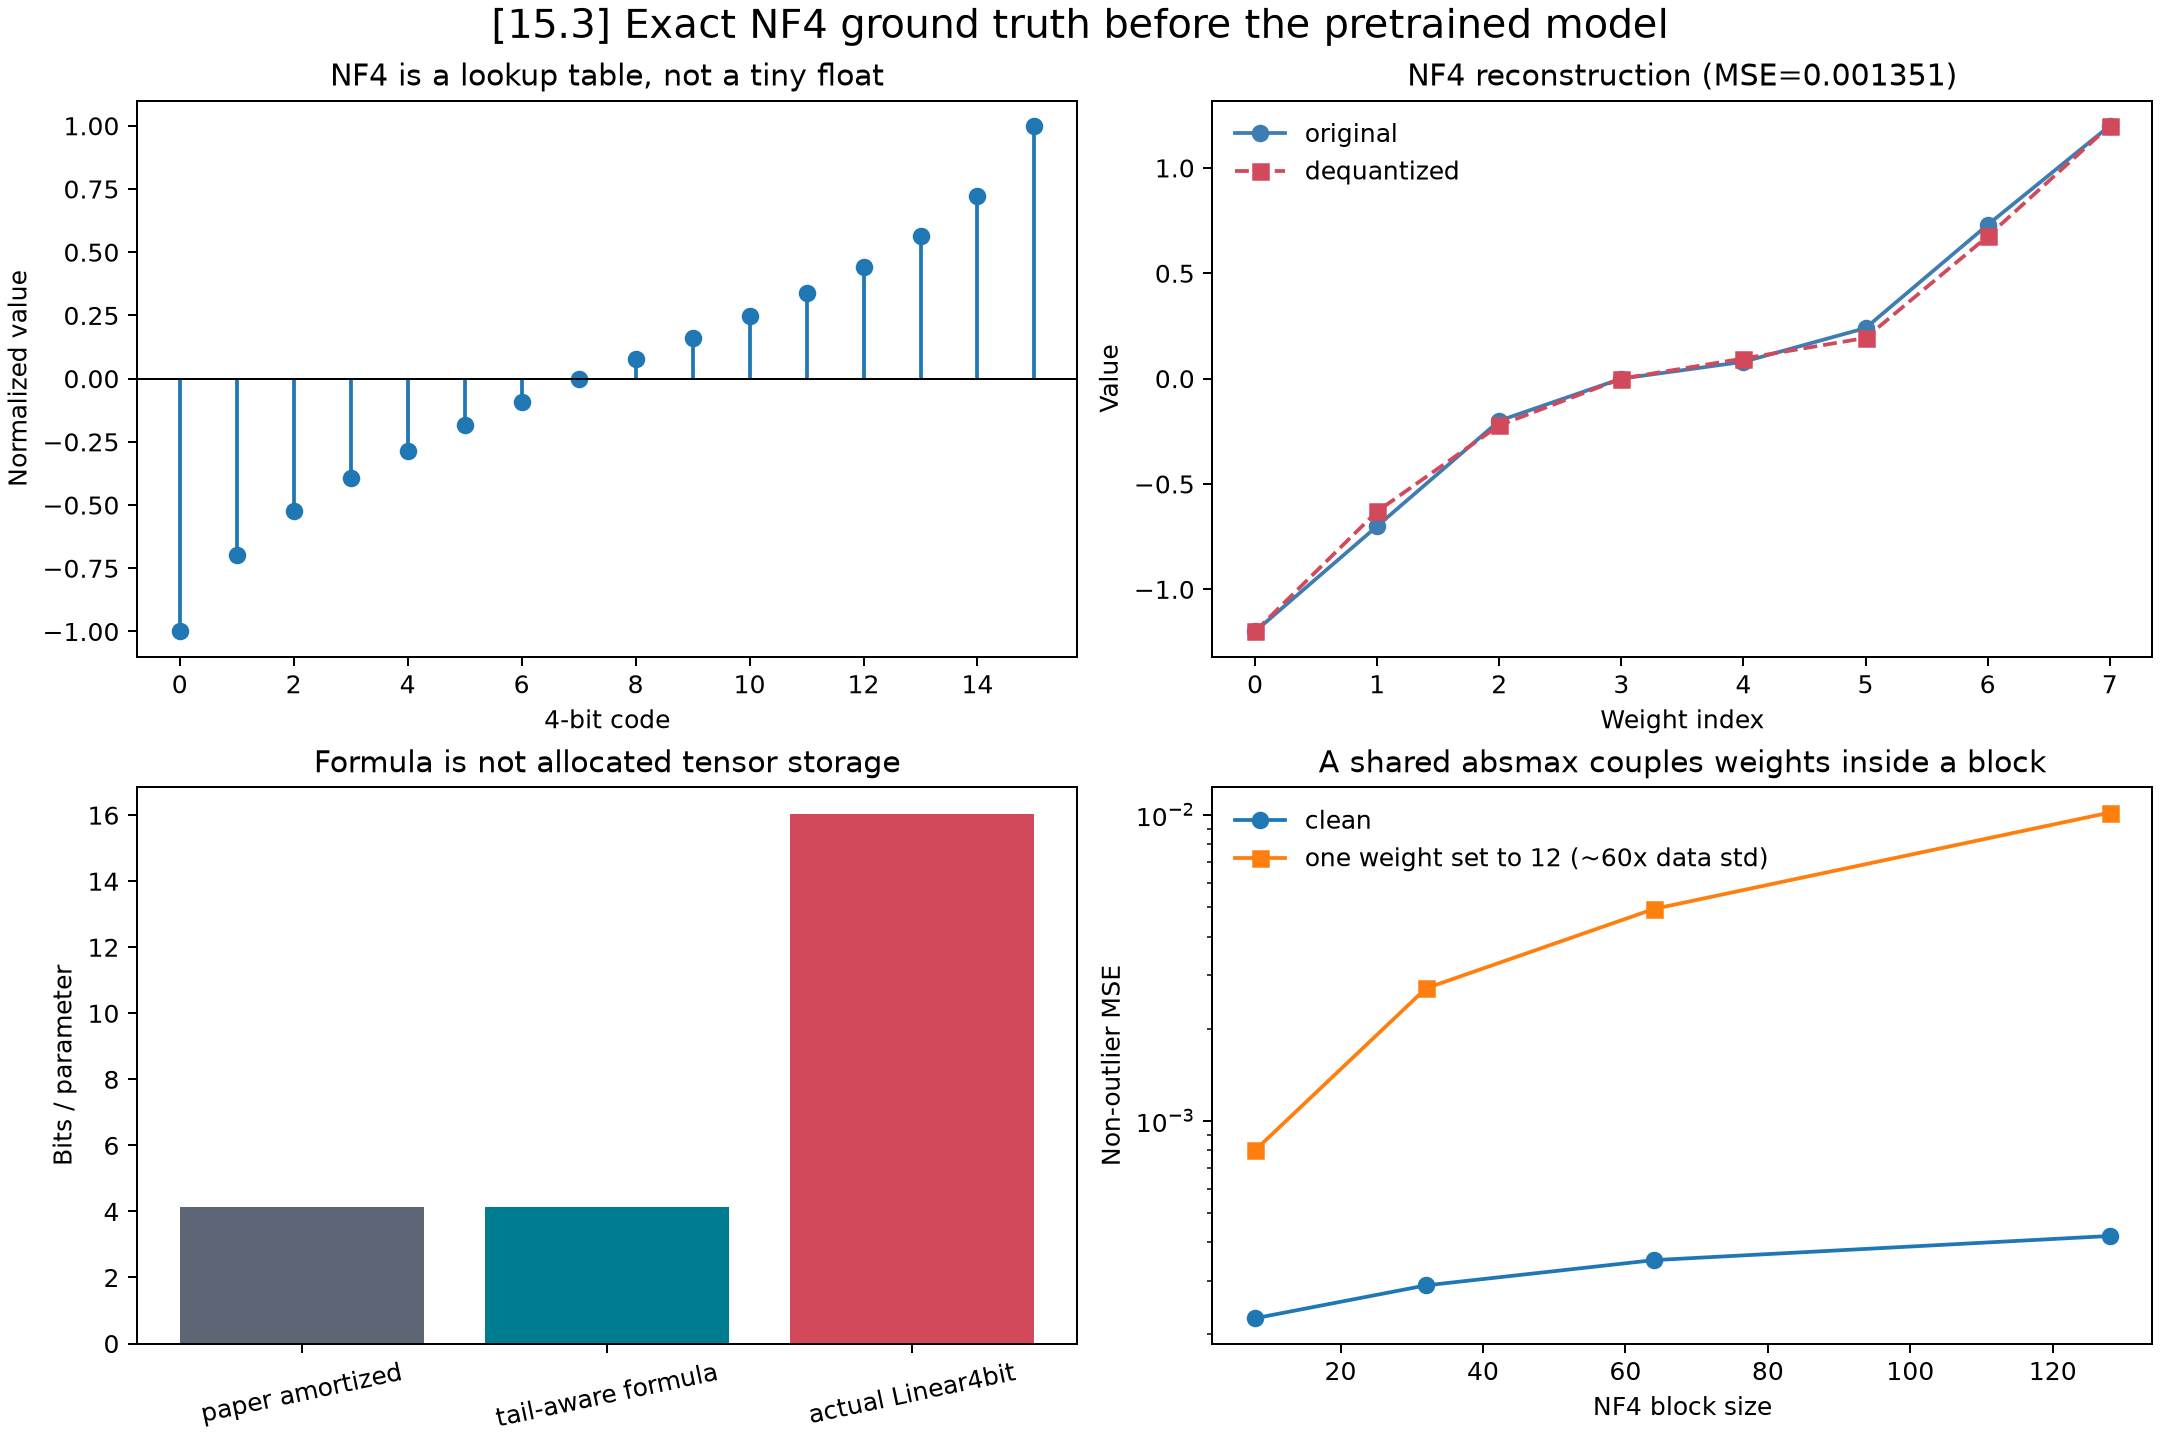

In [17]:
cpu_result = reference.run_cpu_release(
    implementation=learner_functions,
    make_figure=True,
)
assert cpu_result["accepted"] == all(cpu_result["checks"].values())
display({
    "accepted": cpu_result["accepted"],
    "checks": cpu_result["checks"],
    "dataset_sizes": {
        key: cpu_result["dataset"][key]
        for key in ("train_examples", "template_transfer_examples", "unseen_subject_ood_examples")
    },
    "name_only": cpu_result["dataset"]["name_only_baselines"],
})
display(Image(filename=str(ROOT / "chapter15_peft_misalignment/instructions/assets/qlora_nf4_toy_signature.png")))

## 10. Train the Marker Rule on TinyStories

Each method result carries its seed. Acceptance extracts exactly three
unique seeds from returned runs, verifies they match every method payload,
and uses a two-sided 95% Student-t interval with `t(0.975, df=2) =
4.3026527299`. The comparison reports:

- canonical, marker-swap, marker-removal, name-only, random-label, and same-norm behavior;
- paired marker-swap prediction-flip and both-sides-correct rates;
- template-transfer and OOD accuracy plus two-label conditional NLL;
- exact codebook/finiteness audits for every quantized method and seed;
- model tensors, gradients, AdamW tensors, and their non-overlapping resident-state total;
- `resident_training_state_bytes = model_tensor_bytes + gradient_bytes + optimizer_state_bytes`;
- QLoRA-vs-BF16-LoRA and QLoRA-vs-full-BF16 state comparators;
- per-layer spectra, protected full-vocabulary NLL, and peak CUDA allocation.

The generic `run_gpu_test` hook is for the visible section reference. This
notebook calls only `run_cuda_release`, whose implementation argument is
mandatory.

W0905 10:35:00.575000 2255491 .venv/lib/python3.14/site-packages/torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


W0905 10:35:00.586000 2255491 .venv/lib/python3.14/site-packages/torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


Loading weights:   0%|          | 0/108 [00:00<?, ?it/s]

[transformers] GPTNeoForCausalLM LOAD REPORT from: roneneldan/TinyStories-1M
Key                                                               | Status     |  | 
------------------------------------------------------------------+------------+--+-
transformer.h.{0, 1, 2, 3, 4, 5, 6, 7}.attn.attention.bias        | UNEXPECTED |  | 
transformer.h.{0, 1, 2, 3, 4, 5, 6, 7}.attn.attention.masked_bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/108 [00:00<?, ?it/s]

...

[transformers] GPTNeoForCausalLM LOAD REPORT from: roneneldan/TinyStories-1M
Key                                                               | Status     |  | 
------------------------------------------------------------------+------------+--+-
transformer.h.{0, 1, 2, 3, 4, 5, 6, 7}.attn.attention.bias        | UNEXPECTED |  | 
transformer.h.{0, 1, 2, 3, 4, 5, 6, 7}.attn.attention.masked_bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/108 [00:00<?, ?it/s]

[transformers] GPTNeoForCausalLM LOAD REPORT from: roneneldan/TinyStories-1M
Key                                                               | Status     |  | 
------------------------------------------------------------------+------------+--+-
transformer.h.{0, 1, 2, 3, 4, 5, 6, 7}.attn.attention.bias        | UNEXPECTED |  | 
transformer.h.{0, 1, 2, 3, 4, 5, 6, 7}.attn.attention.masked_bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/108 [00:00<?, ?it/s]

[transformers] GPTNeoForCausalLM LOAD REPORT from: roneneldan/TinyStories-1M
Key                                                               | Status     |  | 
------------------------------------------------------------------+------------+--+-
transformer.h.{0, 1, 2, 3, 4, 5, 6, 7}.attn.attention.bias        | UNEXPECTED |  | 
transformer.h.{0, 1, 2, 3, 4, 5, 6, 7}.attn.attention.masked_bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


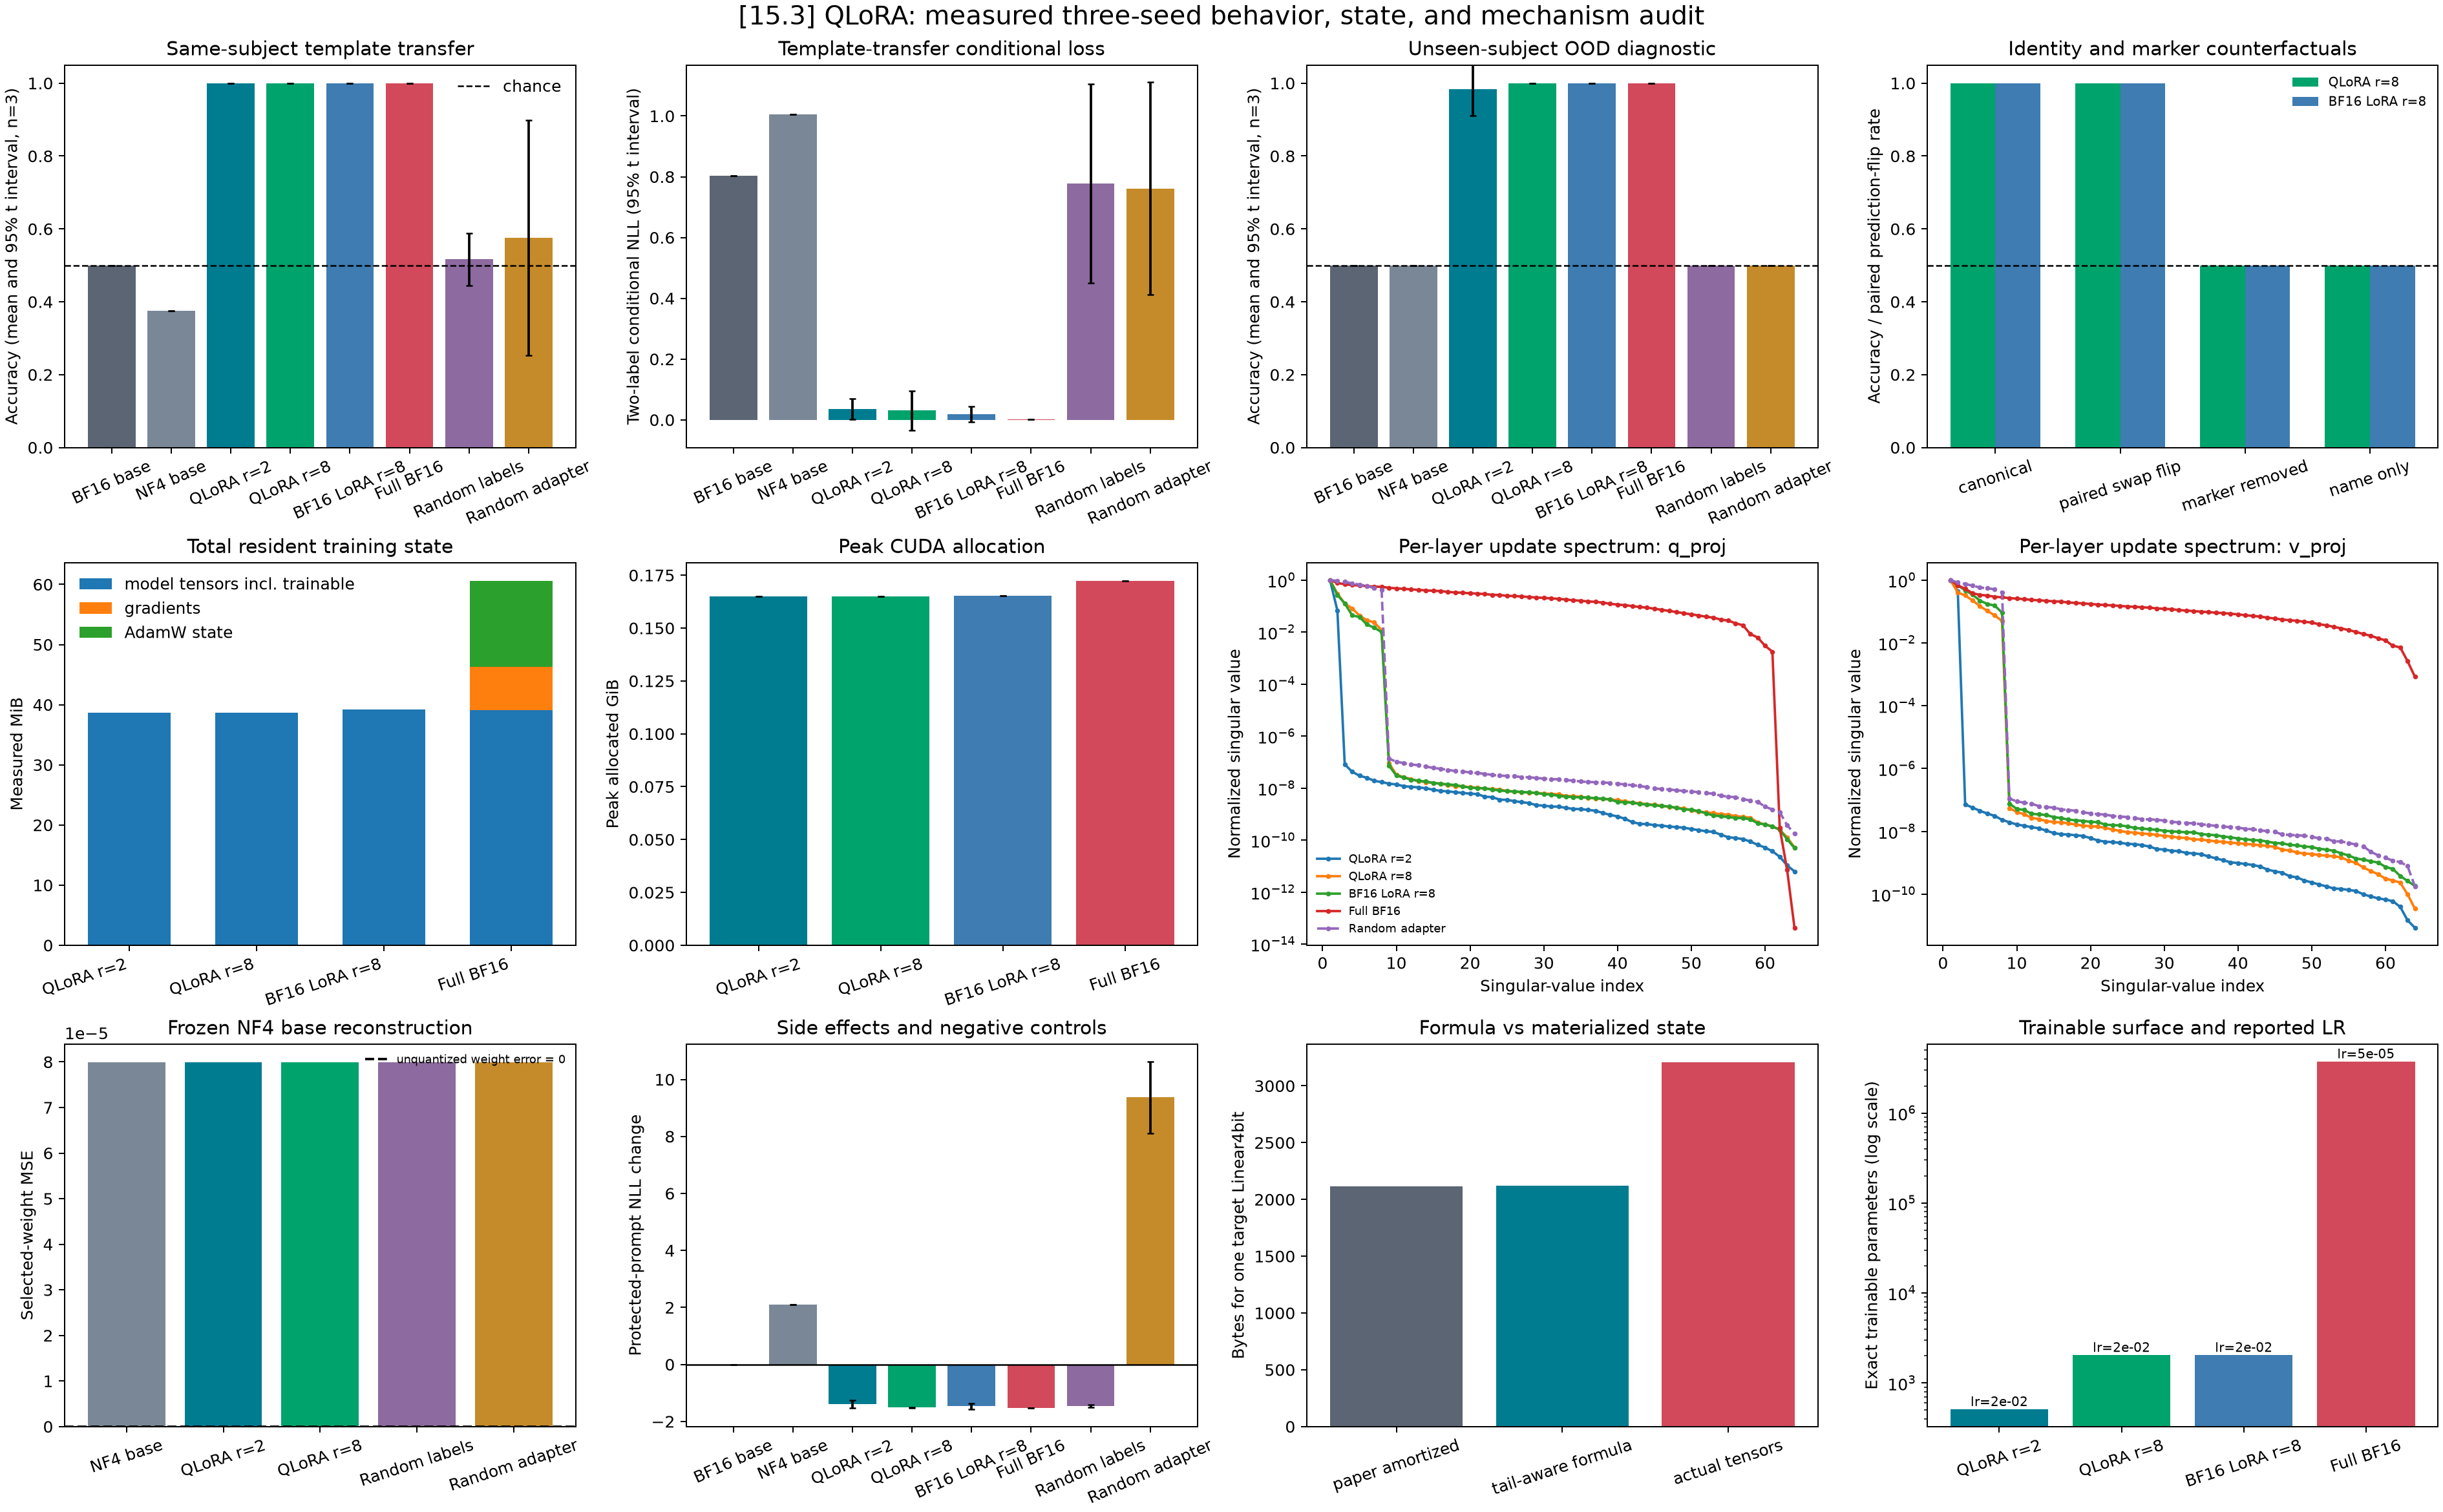

qlora_r8           accuracy=1.000; resident state=38.67 MiB
bf16_lora_r8       accuracy=1.000; resident state=39.18 MiB
full_bf16          accuracy=1.000; resident state=60.58 MiB
random_labels      accuracy=0.517; resident state=38.67 MiB
same_norm_random   accuracy=0.575; resident state=38.65 MiB
Unmet comparison checks: ['dequantized_base_max_diff_max']


In [18]:
def run_cuda_release(max_vram_gb: float = 24.0) -> dict[str, Any]:
    return reference.run_cuda_release(
        implementation=learner_functions,
        max_vram_gb=max_vram_gb,
        steps=32,
        batch_size=12,
    )

RUN_CUDA = t.cuda.is_available() and os.environ.get("ARENA_QLORA_CPU_ONLY") != "1"
if RUN_CUDA:
    cuda_result = run_cuda_release(max_vram_gb=24.0)
    assert cuda_result["accepted"] == all(cuda_result["checks"].values())
    display(Image(filename=str(ROOT / "chapter15_peft_misalignment/instructions/assets/qlora_real_signature_panel.png")))
    for method in ("qlora_r8", "bf16_lora_r8", "full_bf16", "random_labels", "same_norm_random"):
        result = cuda_result["summary"][method]
        print(f"{method:18s} accuracy={result['template_transfer']['accuracy']['mean']:.3f}; "
              f"resident state={result['resident_training_state_mib']['mean']:.2f} MiB")
    print("Unmet comparison checks:", [name for name, passed in cuda_result["checks"].items() if not passed])
else:
    print("CPU mechanics completed. The pretrained comparison requires CUDA and was not run.")

<details><summary>Expected output: measured TinyStories comparison</summary>

The September 5 reference run uses seeds 0, 1, and 2, with 32 updates per
trained method. QLoRA r=8 and BF16 LoRA r=8 both reach 1.000 accuracy on
these 40 template-transfer and 40 narrow OOD examples. Random labels
average 0.517 and random same-norm adapters 0.575 on template transfer;
marker removal and the name-only baseline give 0.500.

Resident training state is 38.67 MiB for QLoRA, 39.18 MiB for BF16 LoRA,
and 60.58 MiB for full BF16. This is about 1.3% savings against BF16 LoRA,
not an eightfold reduction. The original 0.01 dequantized-matmul error
limit fails (maximum 0.03125), so the candidate remains unreleased even
though its behavior and memory checks pass. Thresholds are unchanged.

</details>

<details><summary>Interpreting the curves</summary>

Low rank is enforced by A and B even for random adapters; it is not
evidence of useful learning by itself. Compare their behavior and
protected-prompt loss with the trained adapters. The protected prompts
are also used for replay, so improvement there measures the replay
objective and does not establish general capability preservation.

All seeds solving this tiny rule gives a zero-width seed interval; it
does not imply zero uncertainty on new tasks or examples. The next
diagnostic inspects the small memory gain and failed parity check.

</details>

## Try It Yourself

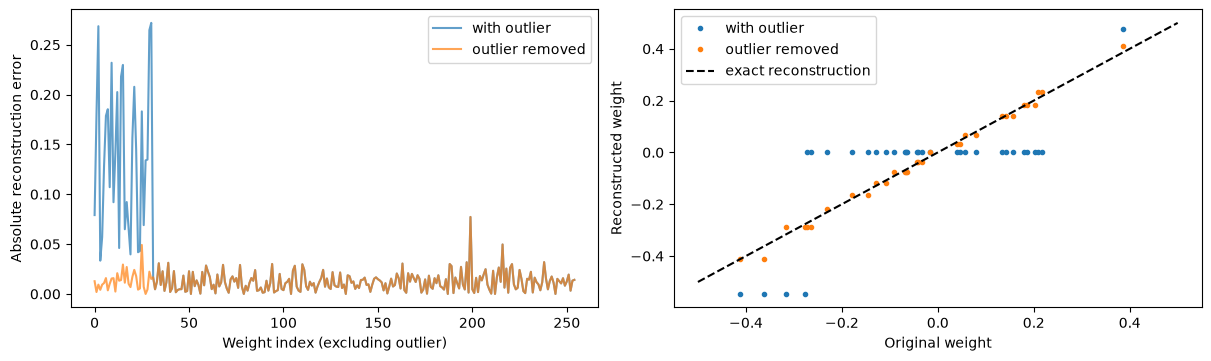

{'block_size': 32,
 'raw_outlier_value': 6.0,
 'non_outlier_mse': 0.003209497081115842}

In [19]:
PLAY_BLOCK_SIZE = 32
PLAY_OUTLIER_VALUE = 6.0
play_generator = t.Generator().manual_seed(7)
play_weights = 0.2 * t.randn(256, generator=play_generator)
play_weights[0] = PLAY_OUTLIER_VALUE
play_reconstructed = dequantize_nf4(quantize_nf4(play_weights, block_size=PLAY_BLOCK_SIZE))
play_clean = play_weights.clone()
play_clean[0] = 0.0
play_clean_rec = dequantize_nf4(quantize_nf4(play_clean, block_size=PLAY_BLOCK_SIZE))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), layout="constrained")
for label, original, reconstructed in (("with outlier", play_weights, play_reconstructed),
                                        ("outlier removed", play_clean, play_clean_rec)):
    axes[0].plot((original[1:] - reconstructed[1:]).abs(), label=label, alpha=0.7)
    axes[1].plot(original[1:33], reconstructed[1:33], ".", label=label)
axes[0].set(xlabel="Weight index (excluding outlier)", ylabel="Absolute reconstruction error")
axes[1].plot([-0.5, 0.5], [-0.5, 0.5], "k--", label="exact reconstruction")
axes[1].set(xlabel="Original weight", ylabel="Reconstructed weight")
for ax in axes: ax.legend()
plt.show()
display({
    "block_size": PLAY_BLOCK_SIZE,
    "raw_outlier_value": PLAY_OUTLIER_VALUE,
    "non_outlier_mse": float((play_weights[1:] - play_reconstructed[1:]).square().mean().item()),
})

In [20]:
_, play_transfer = make_codebook_examples()
play_controls = make_marker_control_examples(play_transfer)
PLAY_INDEX = 0
for condition, example in (("canonical", play_transfer[PLAY_INDEX]),
                            ("marker swap", play_controls["marker_swap"][PLAY_INDEX]),
                            ("marker removed", play_controls["marker_removed"][PLAY_INDEX])):
    print(f"{condition}: {example.prompt}")
    print(f"  paired target: {LABEL_TEXT[example.label]!r}")
print("After marker removal the same prompt occurs with both targets; name alone cannot decide.")

canonical: Using the same codebook, decode Alice's marker dax as
  paired target: ' red'
marker swap: Using the same codebook, decode Alice's marker wug as
  paired target: ' blue'
marker removed: Using the same codebook, decode Alice's marker [marker removed] as
  paired target: ' red'
After marker removal the same prompt occurs with both targets; name alone cannot decide.


### Try It Yourself: inspect memory and arithmetic precision

The small resident-state saving needs an explanation. Count parameters
and buffers separately, then change `PLAY_PARITY_LAYER` or the input
scale. Compare the real BF16 kernel with a dequantized dense layer, and
repeat in FP32 as a precision control. This diagnostic does not change
the registered BF16 parity threshold or the training configuration.

<details><summary>Interpreting the diagnostic</summary>

Eight 2048-by-2048 boolean attention masks occupy 32 MiB in this GPT-Neo
implementation. These buffers and the unquantized embedding table limit
total savings. In the tested runtime, the FP32 comparison agrees closely
while the BF16 comparison exceeds the original 0.01 absolute-error gate.
This supports a precision-dependent difference; it does not prove every
BF16 discrepancy harmless. Keep that failed gate visible.

</details>

Loading weights:   0%|          | 0/108 [00:00<?, ?it/s]

[transformers] GPTNeoForCausalLM LOAD REPORT from: roneneldan/TinyStories-1M
Key                                                               | Status     |  | 
------------------------------------------------------------------+------------+--+-
transformer.h.{0, 1, 2, 3, 4, 5, 6, 7}.attn.attention.bias        | UNEXPECTED |  | 
transformer.h.{0, 1, 2, 3, 4, 5, 6, 7}.attn.attention.masked_bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


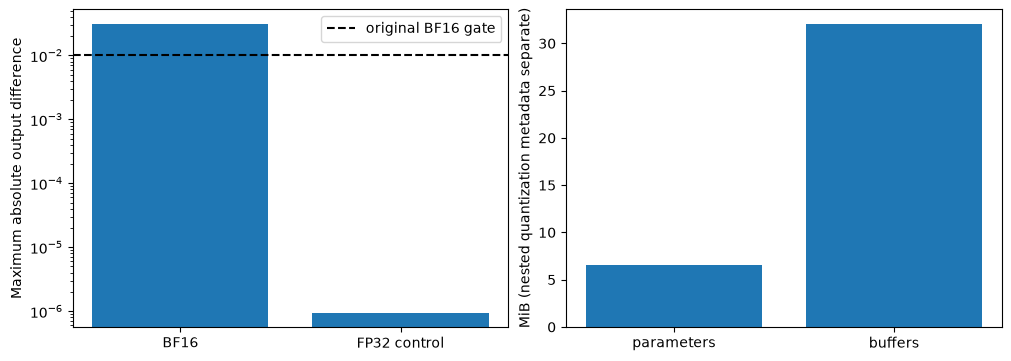

BF16 error 0.03125000; FP32 error 0.00000095


In [21]:
PLAY_PARITY_LAYER = TARGET_MODULES[0]
PLAY_INPUT_SCALE = 1.0
precision_diagnostic = None
if RUN_CUDA:
    diagnostic_model = load_nf4_model(device=t.device("cuda:0"))
    parent, leaf = _get_parent_and_leaf(diagnostic_model, PLAY_PARITY_LAYER)
    diagnostic_layer = getattr(parent, leaf)
    generator = t.Generator(device="cuda").manual_seed(1)
    inputs = PLAY_INPUT_SCALE * t.randn(3, diagnostic_layer.in_features,
                                         generator=generator, device="cuda", dtype=t.bfloat16)
    bf16_error = dequantized_base_max_diff(diagnostic_layer, inputs)
    state32 = copy.copy(diagnostic_layer.weight.quant_state)
    state32.dtype = t.float32
    weight32 = bnb.functional.dequantize_4bit(diagnostic_layer.weight.data, state32)
    diagnostic_layer.compute_dtype = t.float32
    bias32 = None if diagnostic_layer.bias is None else diagnostic_layer.bias.float()
    with t.no_grad():
        dense32 = F.linear(inputs.float(), weight32, bias32)
        fp32_error = float((diagnostic_layer(inputs.float()) - dense32).abs().max())
    precision_diagnostic = {
        "bf16_max_abs_error": bf16_error, "fp32_max_abs_error": fp32_error,
        "parameter_bytes": sum(p.numel() * p.element_size() for p in diagnostic_model.parameters()),
        "buffer_bytes": sum(b.numel() * b.element_size() for b in diagnostic_model.buffers()),
        "layer": PLAY_PARITY_LAYER, "input_scale": PLAY_INPUT_SCALE,
    }
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), layout="constrained")
    axes[0].bar(["BF16", "FP32 control"], [bf16_error, fp32_error])
    axes[0].axhline(0.01, linestyle="--", color="black", label="original BF16 gate")
    axes[0].set(yscale="log", ylabel="Maximum absolute output difference")
    axes[0].legend()
    axes[1].bar(["parameters", "buffers"],
                [precision_diagnostic[k] / 2**20 for k in ("parameter_bytes", "buffer_bytes")])
    axes[1].set(ylabel="MiB (nested quantization metadata separate)")
    plt.show()
    print(f"BF16 error {bf16_error:.8f}; FP32 error {fp32_error:.8f}")
    del diagnostic_layer, parent, diagnostic_model, inputs, weight32, state32, dense32
    gc.collect()
    t.cuda.empty_cache()
else:
    print("This precision and model-buffer diagnostic requires CUDA.")

## Bonus Anomaly Hunt

Register one directional prediction before changing rank, target layer,
block size, nested statistics, or NF4 versus FP4. A useful anomaly is a
case where stored model tensors shrink but total resident state or peak
allocation does not, or where accuracy agrees while two-label conditional
NLL, marker-removal behavior, or protected full-vocabulary NLL diverges.

## Interpreting the Result

Aggregate swap accuracy is redundant on a fully crossed split. The paired
prediction-flip and both-sides-correct rates ask whether predictions follow
the causal marker after the subject is held fixed. Marker-removal and name-only results should be at
chance because the crossed design makes identity uninformative. The memory
claim is only that measured resident state, `model tensors + gradients +
optimizer tensors`, is smaller for QLoRA under explicit comparators. Peak
allocator memory is reported separately and may not follow that ordering.

## Limitations

- Three fixed seeds estimate only optimizer, batching, and initialization variability; the wide t interval is not dataset uncertainty.
- The OOD split changes names and templates but keeps the explicit two-marker rule.
- Two-label conditional NLL says nothing about probability assigned outside ` red` and ` blue`.
- TinyStories-1M and two layer-6 targets do not establish large-model quality or memory scaling.
- Four protected prompts are a guardrail, not a capability benchmark.
- AdamW is measured here; paged optimizers are not reimplemented.
- Callback hashes identify code, and direct-dependency checks catch simple reference aliases.
  They cannot prove correctness or detect arbitrary dynamic delegation.
- CUDA is needed for the pretrained comparison. CPU-only execution covers the mechanics,
  not the behavior or training-memory claims.

## Reading

- Dettmers et al. (2023), [QLoRA](https://arxiv.org/abs/2305.14314)
- Hu et al. (2021), [LoRA](https://arxiv.org/abs/2106.09685)
- Eldan and Li (2023), [TinyStories](https://arxiv.org/abs/2305.07759)